<h1><font color="#113D68" size=6>
TINTOlib: from tabular data to synthetic images
</font></h1>

<h1><font color="#113D68" size=5>
Improving deep learning on tabular data by exploiting synthetic images
</font></h1>

<h1><font color="#113D68" size=4>
Hands-on notebook: transformations, CNN, ViT, hybrid networks, reliable evaluation and explainability
</font></h1>

<br><br>

<div style="text-align: right">
<font color="#113D68" size=3>Manuel Castillo-Cara</font><br>
</div>

---
<a id="indice" name="indice"></a>
<h2><font color="#004D7F" size=5>Index</font></h2>

- [0. Context](#section0)
- [1. Setup](#section1)
- [2. The dataset](#section2)
- [3. Split first, transform later](#section3)
- [4. From rows to images: a gallery of methods](#section4)
  - [4.1. Generating the images](#section41)
  - [4.2. Same patient, ten pictures](#section42)
  - [4.3. Do benign and malignant patients look different?](#section43)
- [5. Where is each variable?](#section5)
- [6. Classical baselines](#section6)
- [7. Images for the neural networks](#section7)
  - [7.1. A real-world pitfall: batch-dependent scaling](#section71)
  - [7.2. Final tensors](#section72)
- [8. Four architectures](#section8)
  - [8.1. CNN encoder](#section81)
  - [8.2. Vision Transformer encoder](#section82)
  - [8.3. Image-only and hybrid heads](#section83)
- [9. Training on one split](#section9)
  - [9.1. A stable training recipe](#section91)
  - [9.2. A first look at the results](#section92)
- [10. Reliable evaluation](#section10)
  - [10.1. Why one split is not enough](#section101)
  - [10.2. Protocol: repeated stratified cross-validation](#section102)
  - [10.3. Running the protocol](#section103)
  - [10.4. Performance estimates](#section104)
  - [10.5. Are the differences real? Corrected statistical tests](#section105)
  - [10.6. How to report the results](#section106)
- [11. Explainability for the CNN and the ViT](#section11)
  - [11.1. Three explanation tools](#section111)
  - [11.2. Local explanation](#section112)
  - [11.3. Global explanation](#section113)
  - [11.4. Are the explanations faithful?](#section114)
  - [11.5. Does removing the least important variables help?](#section115)
- [12. Conclusions](#section12)
- [13. Exercises](#section13)
- [14. References](#section14)

<a id="section0" name="section0"></a>
# <font color="#004D7F" size=6>0. Context</font>

Deep learning dominates images, text and audio, yet on **tabular data** gradient-boosted trees usually still win. One reason is structure: a CNN or a Vision Transformer expects neighbouring pixels to be related, while the columns of a table have no natural order.

**The idea behind TINTOlib** is to transform every row of a table into a small *synthetic image* in which related variables become neighbouring pixels, and then let vision architectures learn from it. Figure 1 summarises the whole pipeline that this notebook implements step by step.

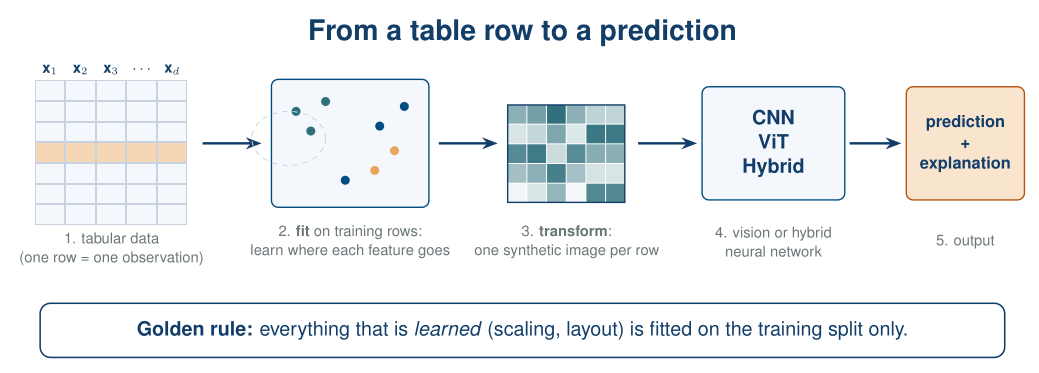

<p style="text-align:center; color:#555555;"><em><strong>Figure 1.</strong> From a table row to a prediction. A transformation is <strong>fitted</strong> on the training rows, every row is then <strong>transformed</strong> into a synthetic image, and a vision or hybrid network learns from it. The explanation maps pixels back to the original variables.</em></p>

<div class="alert alert-info">
<strong>Learning objectives.</strong><br>
By the end of this notebook you should be able to transform a tabular dataset with several TINTOlib methods, explain how the main families of methods differ, build CNN, ViT and hybrid (CNN+MLP, ViT+MLP) models in PyTorch, <strong>evaluate them reliably</strong> with repeated cross-validation, confidence intervals and corrected statistical tests, and explain the CNN and the ViT in terms of the original variables while checking that the explanations are faithful.
</div>

<div class="alert alert-warning">
<strong>Running environment.</strong><br>
The notebook is designed for <strong>Google Colab</strong>; a free CPU runtime is enough. Sections 1–9 and 11 take about 5 minutes; the reliable evaluation of Section 10 trains every network 10 times and takes about 12 more minutes on a CPU (a GPU runtime makes it faster). REFINED needs MPI: the setup cell installs it on Colab, and if that fails the notebook skips REFINED and carries on. Locally you need Python ≥ 3.9 with PyTorch, scikit-learn, SciPy, matplotlib and TINTOlib.
</div>

---
<div style="text-align: right">
<font size=5>
<a href="#indice">Back to index</a>
</font>
</div>

<a id="section1" name="section1"></a>
# <font color="#004D7F" size=6>1. Setup</font>

Colab already includes PyTorch, scikit-learn, SciPy and matplotlib. We install **TINTOlib** and, for REFINED, an MPI runtime plus `mpi4py`.

In [1]:
%pip install -q TINTOlib
# Optional, only for REFINED: an MPI runtime and mpi4py. The last line reports whether REFINED can run.
!apt-get -qq install -y openmpi-bin libopenmpi-dev > /dev/null 2>&1; pip install -q mpi4py > /dev/null 2>&1
!which mpirun > /dev/null && python -c "import mpi4py" 2>/dev/null && echo "MPI available: REFINED will run" || echo "MPI not available: REFINED will be skipped"

Note: you may need to restart the kernel to use updated packages.
MPI not available: REFINED will be skipped


In [2]:
import os, copy, math, random, shutil, time, warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.patches import Patch
from scipy import stats
from scipy.stats import spearmanr

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, RepeatedStratifiedKFold
from sklearn.preprocessing import MinMaxScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score, roc_auc_score,
                             brier_score_loss)

# TINTOlib: one class per transformation method, all with the same fit / transform interface
from TINTOlib.tinto import TINTO
from TINTOlib.igtd import IGTD
from TINTOlib.refined import REFINED
from TINTOlib.deepInsight import DeepInsight
from TINTOlib.fotomics import Fotomics
from TINTOlib.barGraph import BarGraph
from TINTOlib.featureWrap import FeatureWrap
from TINTOlib.clusters import Clusters

warnings.filterwarnings("ignore")
SEED = 42

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed()
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch", torch.__version__, "| device:", DEVICE)

# Palette and a compact figure style
NAVY, TEAL, ORANGE, GREY = "#113D68", "#2E6F7B", "#E8A65A", "#7F8C9A"
plt.rcParams.update({"figure.dpi": 90, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titlesize": 10, "axes.titlecolor": NAVY, "font.size": 9})

PyTorch 2.9.1 | device: cpu


---
<div style="text-align: right">
<font size=5>
<a href="#indice">Back to index</a>
</font>
</div>

<a id="section2" name="section2"></a>
# <font color="#004D7F" size=6>2. The dataset</font>

We use the **Breast Cancer Wisconsin** dataset, shipped with scikit-learn, so nothing needs to be downloaded:

- **569 patients** and **30 numeric features** computed from a digitised image of a breast mass;
- each of **10 measurements** (radius, texture, perimeter, area, smoothness, compactness, concavity, concave points, symmetry and fractal dimension) appears three times: its **mean**, its **standard error** and its **worst** value. These groups of strongly correlated variables are exactly what learned image layouts try to exploit, so the images are easy to read;
- **binary task:** malignant vs. benign.

> In scikit-learn, `0 = malignant` and `1 = benign`. We flip the label so that **1 = malignant** is the positive class.

In [3]:
data = load_breast_cancer(as_frame=True)
df = data.frame.copy()
df.columns = [c.replace(" ", "_") for c in df.columns]
df["target"] = (data.target == 0).astype(int)          # 1 = malignant, 0 = benign

FEATURES = [c for c in df.columns if c != "target"]
print(f"{df.shape[0]} patients x {len(FEATURES)} features")
df.head()

569 patients x 30 features


,mean_radius,mean_texture,mean_perimeter,mean_area,mean_smoothness,mean_compactness,mean_concavity,mean_concave_points,mean_symmetry,mean_fractal_dimension,...,worst_texture,worst_perimeter,worst_area,worst_smoothness,worst_compactness,worst_concavity,worst_concave_points,worst_symmetry,worst_fractal_dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,1
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,1
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,1
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,1
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,1


TINTOlib expects a **tidy table**: one row per observation, numeric features and the **target as the last column**. That is exactly what we have.

The correlation matrix shows the blocks of strongly related variables, the structure that a good image layout should place close together.

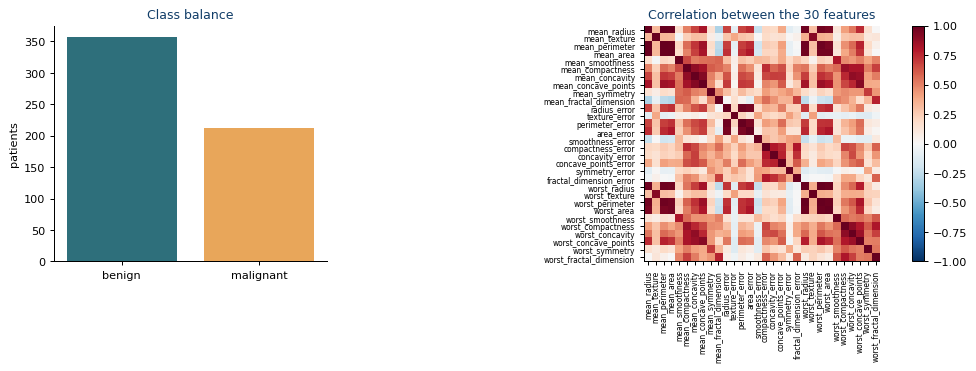

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), gridspec_kw={"width_ratios": [1, 2.4]})

counts = df["target"].map({0: "benign", 1: "malignant"}).value_counts()
axes[0].bar(counts.index, counts.values, color=[TEAL, ORANGE])
axes[0].set_title("Class balance")
axes[0].set_ylabel("patients")

im = axes[1].imshow(df[FEATURES].corr(), cmap="RdBu_r", vmin=-1, vmax=1)
axes[1].set_title("Correlation between the 30 features")
axes[1].set_xticks(range(len(FEATURES)))
axes[1].set_xticklabels(FEATURES, rotation=90, fontsize=6)
axes[1].set_yticks(range(len(FEATURES)))
axes[1].set_yticklabels(FEATURES, fontsize=6)
fig.colorbar(im, ax=axes[1], fraction=0.03)
plt.tight_layout()
plt.show()

---
<div style="text-align: right">
<font size=5>
<a href="#indice">Back to index</a>
</font>
</div>

<a id="section3" name="section3"></a>
# <font color="#004D7F" size=6>3. Split first, transform later</font>

Many TINTOlib methods **learn** something from the data: a scaler, a 2-D projection, an optimal arrangement of features. That learning must use **training rows only**; validation and test rows are transformed afterwards with the frozen method, exactly as with a scikit-learn scaler (Figure 2).

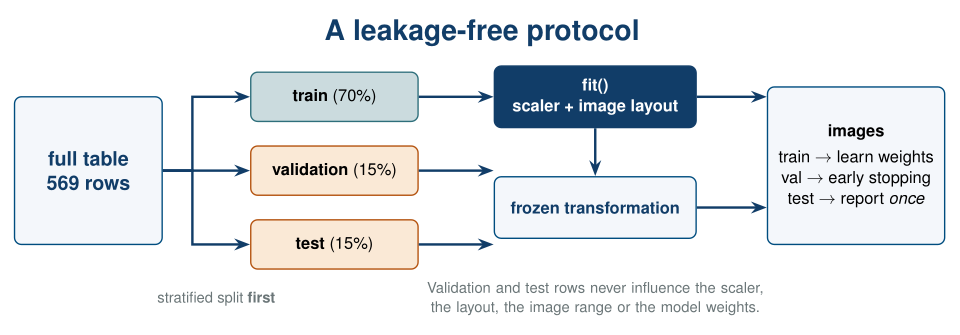

<p style="text-align:center; color:#555555;"><em><strong>Figure 2.</strong> Leakage-free protocol. The table is split first; the scaler and the image layout are fitted on the training split and then applied, frozen, to validation and test. The test split is used once, to report the final results.</em></p>

In Sections 3–9 we use **one** stratified 70/15/15 split. It is the clearest way to follow the pipeline step by step, and Section 11 reuses it to explain the models. It is **not** enough to estimate performance reliably on 569 patients; Section 10 repeats the whole pipeline with cross-validation to obtain estimates that can be reported.

In [5]:
train_df, temp_df = train_test_split(df, test_size=0.30, stratify=df["target"], random_state=SEED)
val_df, test_df = train_test_split(temp_df, test_size=0.50, stratify=temp_df["target"], random_state=SEED)
train_df, val_df, test_df = [d.reset_index(drop=True) for d in (train_df, val_df, test_df)]

SPLITS = {"train": train_df, "val": val_df, "test": test_df}
for name, d in SPLITS.items():
    print(f"{name:<5}: {len(d):3d} patients, {d['target'].mean():.0%} malignant")

train: 398 patients, 37% malignant
val  :  85 patients, 38% malignant
test :  86 patients, 37% malignant


---
<div style="text-align: right">
<font size=5>
<a href="#indice">Back to index</a>
</font>
</div>

<a id="section4" name="section4"></a>
# <font color="#004D7F" size=6>4. From rows to images: a gallery of methods</font>

Every TINTOlib method follows the same two steps:

```python
method.fit(train_df)                          # learn the transformation on training rows
method.transform(test_df, folder="img/test")  # write one image per row + an index CSV
```

The methods fall into three families (Figure 3).

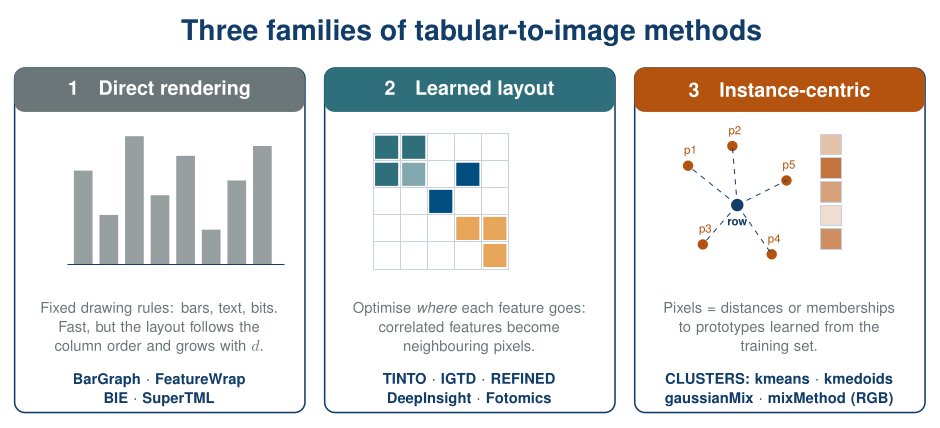

<p style="text-align:center; color:#555555;"><em><strong>Figure 3.</strong> Three families of tabular-to-image methods. <strong>Direct rendering</strong> draws the values with fixed rules, <strong>learned layouts</strong> optimise where each feature is placed, and <strong>instance-centric</strong> methods (CLUSTERS) encode how a row relates to prototypes learned from the training set.</em></p>

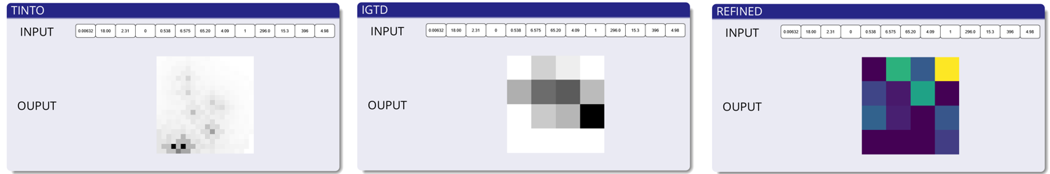

<p style="text-align:center; color:#555555;"><em><strong>Figure 4.</strong> The three classic learned layouts on the same input row: <strong>TINTO</strong> (PCA or t-SNE projection, optional blurring), <strong>IGTD</strong> (optimised permutation on a grid) and <strong>REFINED</strong> (multidimensional scaling plus hill-climbing).</em></p>

<a id="section41" name="section41"></a>
## <font color="#004D7F" size=5>4.1. Generating the images</font>

The helper below wraps the two steps, writes the images to disk and reads them back in row order. It receives the partitions as an argument, so Section 10 can reuse it inside every cross-validation fold.

<div class="alert alert-info">
<strong>PNG or npy?</strong><br>
Learned-layout methods can save the raw numeric matrix (<code>format="npy"</code>) instead of a PNG. A PNG is colour-scaled image by image, so the absolute level of a pixel is not comparable across patients; <code>npy</code> keeps the exact values. We use <code>npy</code> whenever the method allows it.
</div>

In [6]:
IMG_ROOT = "tintolib_images"

def to_gray(imgs):
    # PNG files come back as RGB(A); collapse them to one channel. 2-D arrays pass through.
    return imgs[..., :3].mean(-1) if imgs.ndim == 4 else imgs

def read_images(folder):
    # TINTOlib writes the images plus an index CSV ('images' = relative path, 'values' = label)
    index = pd.read_csv(os.path.join(folder, "supervised.csv"))
    imgs = []
    for rel_path in index["images"]:
        path = os.path.join(folder, rel_path)
        img = np.load(path) if path.endswith(".npy") else plt.imread(path)
        imgs.append(img.astype(np.float32))
    return np.stack(imgs), index["values"].to_numpy()

def to_images(method, name, splits=None, verbose=True):
    # Fit on the TRAINING partition only, then transform every partition with the frozen method
    splits = SPLITS if splits is None else splits
    out = os.path.join(IMG_ROOT, name)
    shutil.rmtree(out, ignore_errors=True)
    t0 = time.time()
    method.fit(splits["train"])
    images = {}
    for split, frame in splits.items():
        folder = os.path.join(out, split)
        method.transform(frame, folder=folder)
        images[split], labels = read_images(folder)
        assert (labels == frame["target"].to_numpy()).all(), "image order does not match row order"
    if verbose:
        shape = "x".join(str(s) for s in images["train"].shape[1:3])
        print(f"{name:<22} {shape:>7} pixels   {time.time() - t0:5.1f} s")
    return images

In [7]:
gallery_methods = {
    # Learned layout (parametric)
    "TINTO":              TINTO(problem="supervised", pixels=20, blur=False, format="npy", random_seed=SEED),
    "TINTO + blur":       TINTO(problem="supervised", pixels=20, blur=True, format="npy", random_seed=SEED),
    "IGTD":               IGTD(problem="supervised", scale=[5, 6], max_step=2000, val_step=100, format="npy", random_seed=SEED),
    "REFINED":            REFINED(problem="supervised", hcIterations=5, n_processors=2, format="npy", random_seed=SEED),
    "DeepInsight":        DeepInsight(image_dim=12, problem="supervised", format="npy", random_seed=SEED),
    "Fotomics":           Fotomics(image_dim=12, problem="supervised", format="npy", random_seed=SEED),
    # Direct rendering (non-parametric)
    "BarGraph":           BarGraph(problem="supervised", pixel_width=2, gap=1),
    "FeatureWrap":        FeatureWrap(problem="supervised", size=(8, 8), bins=10),
    # Instance-centric (CLUSTERS)
    "CLUSTERS kmedoids":  Clusters(problem="supervised", algorithm="kmedoids", n_clusters=16, random_seed=SEED),
    "CLUSTERS mixMethod": Clusters(problem="supervised", algorithm="mixMethod",
                                   ensamMethod=["kmeans", "gaussianMix", "kmedoids"], n_clusters=16, random_seed=SEED),
}
LEARNED, DIRECT, INSTANCE = "learned layout", "direct", "instance-centric"
FAMILY = {"TINTO": LEARNED, "TINTO + blur": LEARNED, "IGTD": LEARNED, "REFINED": LEARNED,
          "DeepInsight": LEARNED, "Fotomics": LEARNED, "BarGraph": DIRECT, "FeatureWrap": DIRECT,
          "CLUSTERS kmedoids": INSTANCE, "CLUSTERS mixMethod": INSTANCE + " (RGB)"}

gallery = {}
for name, method in gallery_methods.items():
    try:
        gallery[name] = to_images(method, name.replace(" ", "_"))
    except Exception as err:                       # REFINED needs MPI; skip it if MPI is not available
        print(f"{name:<22} skipped: {type(err).__name__}: {str(err)[:80]}")

TINTO                    20x20 pixels     0.2 s
TINTO_+_blur             20x20 pixels     0.2 s
IGTD                       5x6 pixels     0.2 s
REFINED                    6x6 pixels     2.5 s
DeepInsight              12x12 pixels     0.2 s
Fotomics                 12x12 pixels     0.2 s
BarGraph                 91x91 pixels     0.4 s
FeatureWrap                8x8 pixels     0.3 s
CLUSTERS_kmedoids          4x4 pixels     0.2 s
CLUSTERS_mixMethod         4x4 pixels     0.2 s


<a id="section42" name="section42"></a>
## <font color="#004D7F" size=5>4.2. Same patient, ten pictures</font>

Here is **the same test patient** drawn by every method. Every picture re-encodes the same row of 30 numbers.

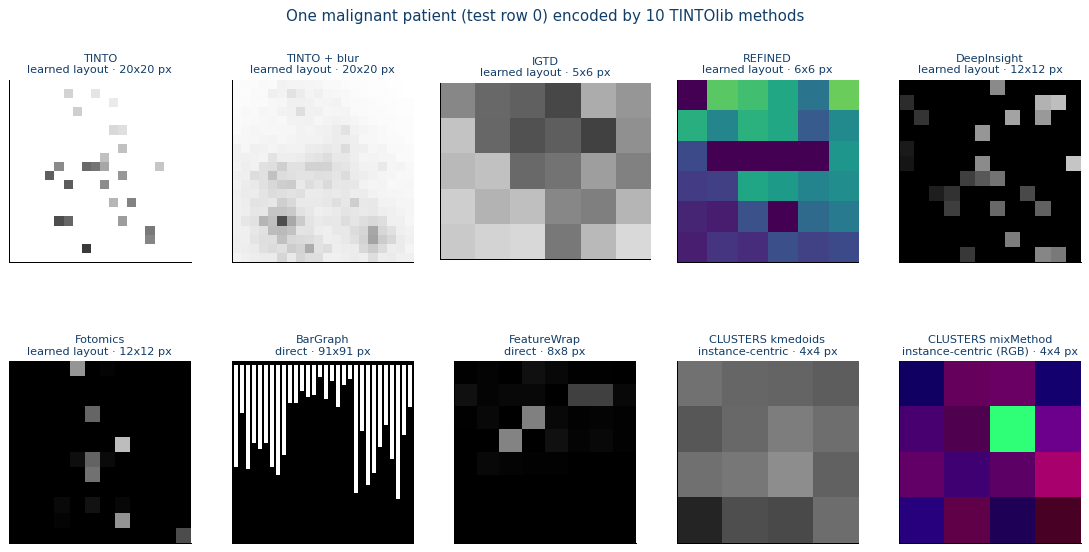

In [8]:
def show_img(ax, name, img):
    # Same colour map and value range for every patient of a given method
    if img.ndim == 3:                                   # RGB(A): show as is
        ax.imshow(img, interpolation="nearest")
    else:
        train = gallery[name]["train"]
        cmap = getattr(gallery_methods[name], "cmap", None) or "gray"
        ax.imshow(img, cmap=cmap, vmin=train.min(), vmax=train.max(), interpolation="nearest")
    ax.set_xticks([]); ax.set_yticks([])

patient = int(np.flatnonzero(test_df["target"].to_numpy() == 1)[0])   # first malignant test patient

n = len(gallery)
fig, axes = plt.subplots(2, math.ceil(n / 2), figsize=(2.5 * math.ceil(n / 2), 6.2))
for ax in axes.ravel():
    ax.axis("off")
for ax, (name, imgs) in zip(axes.ravel(), gallery.items()):
    img = imgs["test"][patient]
    ax.axis("on")
    show_img(ax, name, img)
    ax.set_title(f"{name}\n{FAMILY[name]} · {img.shape[0]}x{img.shape[1]} px", fontsize=9)
fig.suptitle(f"One malignant patient (test row {patient}) encoded by {n} TINTOlib methods", fontsize=12, color=NAVY)
plt.tight_layout(rect=(0, 0, 1, 0.93))
plt.subplots_adjust(hspace=0.55)
plt.show()

**What to notice**

- **Learned layouts** (TINTO, IGTD, REFINED, DeepInsight, Fotomics) are compact: one pixel, or a small blob, per feature, placed by a projection or an optimisation fitted on the training data.
- **Blurring** in TINTO spreads each feature over its neighbours, which convolutional filters like, but it makes pixels harder to trace back to a single variable.
- **Direct renderings** (BarGraph, FeatureWrap) follow the column order of the table and grow with the number of features.
- **CLUSTERS** does not draw the variables at all: with `kmedoids`, its 16 pixels are distances to 16 prototype patients learned from the training set; `mixMethod` stacks three such views (k-means, Gaussian mixture, k-medoids) as the **red, green and blue channels** of one image.
- **REFINED** places the 30 features on a 6×6 grid (36 cells): the cells without a feature keep a constant value, visible as the uniform dark band in Section 4.3. The gallery shows it with its default *viridis* colour map.

<a id="section43" name="section43"></a>
## <font color="#004D7F" size=5>4.3. Do benign and malignant patients look different?</font>

For four methods we average the training images of each class and subtract them.

<div class="alert alert-info">
<strong>How to read these maps.</strong><br>
Every image here has a <strong>single channel</strong>. The colours are a <em>colour map</em> applied for display, not RGB channels: the first two columns use a grey scale, and the difference uses a red–blue scale (red: the pixel is, on average, higher for malignant patients; blue: higher for benign ones). Note that <strong>IGTD paints high values dark</strong> (a TINTOlib convention), so for IGTD a feature that is larger in malignant patients appears <em>blue</em>, while for TINTO it appears <em>red</em>.
</div>

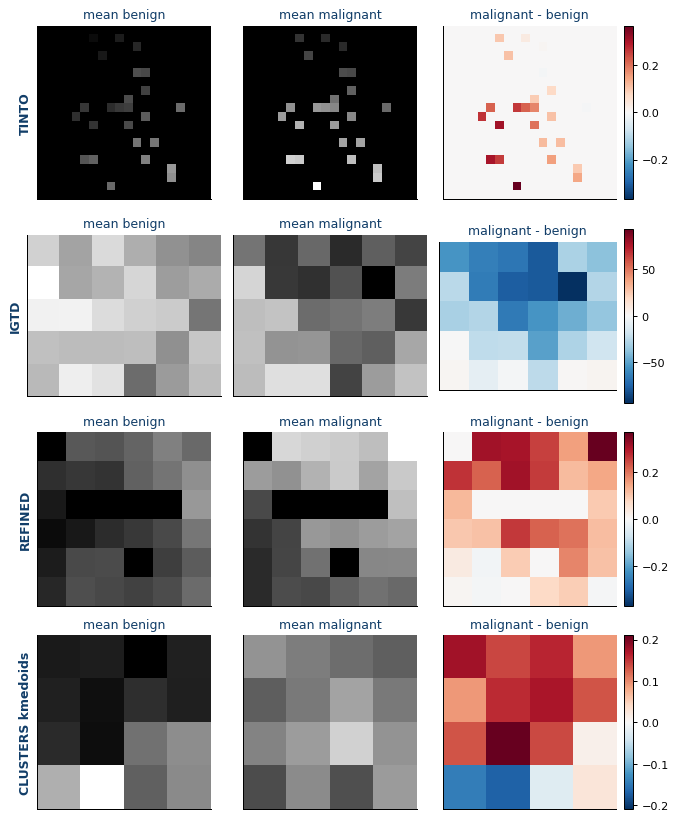

In [9]:
show = [m for m in ["TINTO", "IGTD", "REFINED", "CLUSTERS kmedoids"] if m in gallery]
y_train = train_df["target"].to_numpy()

fig, axes = plt.subplots(len(show), 3, figsize=(7.6, 2.3 * len(show)))
for row, name in zip(np.atleast_2d(axes), show):
    imgs = to_gray(gallery[name]["train"])
    mean_benign, mean_malig = imgs[y_train == 0].mean(0), imgs[y_train == 1].mean(0)
    diff = mean_malig - mean_benign
    lim = np.abs(diff).max()
    vmin, vmax = min(mean_benign.min(), mean_malig.min()), max(mean_benign.max(), mean_malig.max())
    row[0].imshow(mean_benign, cmap="gray", vmin=vmin, vmax=vmax, interpolation="nearest")
    row[1].imshow(mean_malig, cmap="gray", vmin=vmin, vmax=vmax, interpolation="nearest")
    im = row[2].imshow(diff, cmap="RdBu_r", vmin=-lim, vmax=lim, interpolation="nearest")
    fig.colorbar(im, ax=row[2], fraction=0.046, pad=0.04)
    for ax, title in zip(row, ["mean benign", "mean malignant", "malignant - benign"]):
        ax.set_title(title); ax.set_xticks([]); ax.set_yticks([])
    row[0].set_ylabel(name, fontsize=10, color=NAVY, fontweight="bold")
plt.tight_layout()
plt.show()

The class signal is visible to the naked eye, and **each method exposes it differently**. This is why, in large benchmarks, the choice of transformation matters more than the choice of network.

---
<div style="text-align: right">
<font size=5>
<a href="#indice">Back to index</a>
</font>
</div>

<a id="section5" name="section5"></a>
# <font color="#004D7F" size=6>5. Where is each variable?</font>

To explain a model trained on synthetic images we need a **map from pixels back to variables**. We compute it empirically, in a way that works for any method (Figure 5).

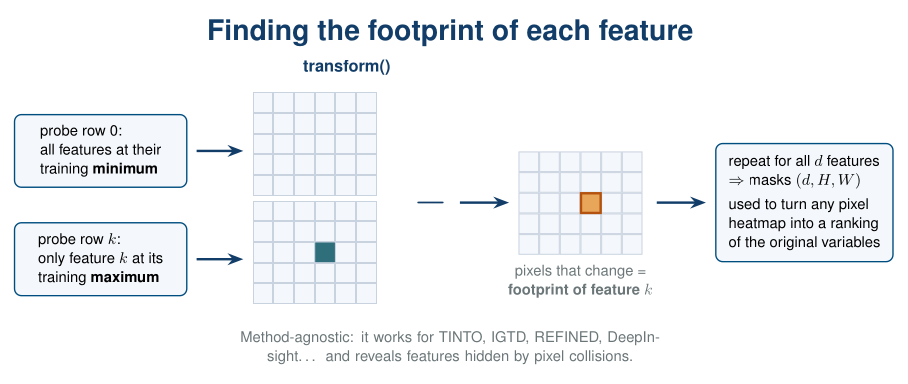

<p style="text-align:center; color:#555555;"><em><strong>Figure 5.</strong> Finding the footprint of each feature. A probe row with every feature at its training minimum is compared with probes in which a single feature is raised to its maximum; the pixels that change are that feature's footprint.</em></p>

In [10]:
MEASURES = ["radius", "texture", "perimeter", "area", "smoothness", "compactness",
            "concavity", "concave_points", "symmetry", "fractal_dimension"]
GROUP_COLOUR = {"mean": TEAL, "error": GREY, "worst": ORANGE}

def group_of(name):
    return "mean" if name.startswith("mean_") else "worst" if name.startswith("worst_") else "error"

def measure_of(name):
    return name.replace("mean_", "").replace("worst_", "").replace("_error", "")

def feature_footprints(method, train_frame=None, threshold=0.5):
    # Boolean masks (n_features, H, W): which pixels move when each feature moves
    train_frame = train_df if train_frame is None else train_frame
    lo, hi = train_frame[FEATURES].min(), train_frame[FEATURES].max()
    rows = [lo.to_numpy(copy=True)]
    for k in range(len(FEATURES)):
        r = lo.to_numpy(copy=True)
        r[k] = hi.iloc[k]
        rows.append(r)
    probe = pd.DataFrame(rows, columns=FEATURES)
    probe["target"] = 0
    folder = os.path.join(IMG_ROOT, "_probe")
    shutil.rmtree(folder, ignore_errors=True)
    method.transform(probe, folder=folder)
    imgs = to_gray(read_images(folder)[0])
    diff = np.abs(imgs[1:] - imgs[0])
    peak = diff.reshape(len(FEATURES), -1).max(axis=1)
    masks = diff >= threshold * peak[:, None, None]
    masks[peak == 0] = False          # features that never show up in the image
    return masks

def plot_layout(masks, title, ax, label="name"):
    # Colour each footprint by feature group and label it with the measurement name or number
    H, W = masks.shape[1:]
    canvas = np.ones((H, W, 3)) * np.array([0.96, 0.97, 0.98])
    for k, m in enumerate(masks):
        canvas[m] = np.array(mcolors.to_rgb(GROUP_COLOUR[group_of(FEATURES[k])]))
    ax.imshow(canvas, interpolation="nearest")
    ax.set_xticks(np.arange(-0.5, W, 1), minor=True)
    ax.set_yticks(np.arange(-0.5, H, 1), minor=True)
    ax.grid(which="minor", color="white", lw=2 if H < 10 else 0.8)
    ax.tick_params(which="both", length=0)
    ax.set_xticklabels([]); ax.set_yticklabels([])
    for k, m in enumerate(masks):
        if m.any():
            r, c = np.argwhere(m).mean(0)
            meas = measure_of(FEATURES[k])
            text = meas.replace("_", "\n") if label == "name" else str(MEASURES.index(meas) + 1)
            ax.text(c, r, text, ha="center", va="center", color="white", fontweight="bold",
                    fontsize=9 if label == "name" else 7.5)
    ax.set_title(title, fontsize=11)

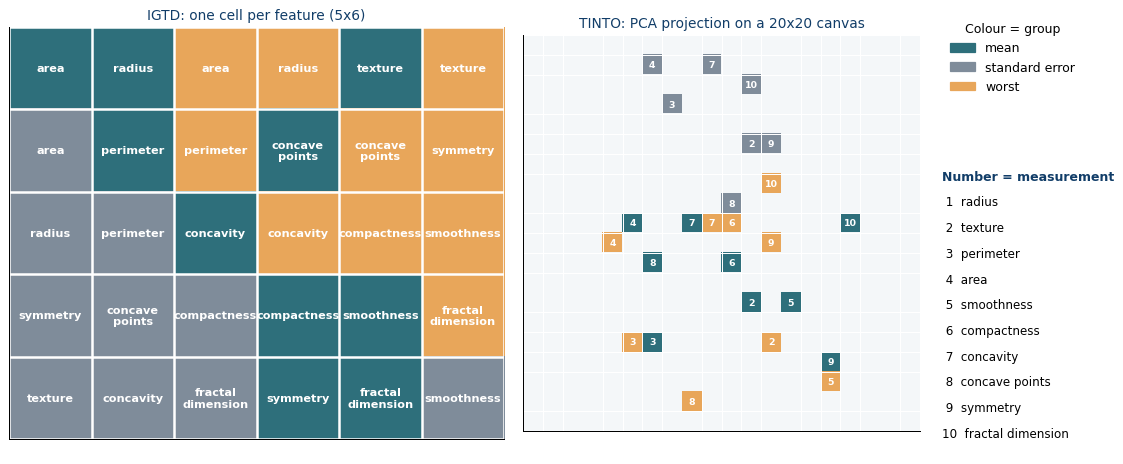

TINTO: 25 of 30 features are visible.
Hidden because another feature was projected onto the same pixel: mean_radius, radius_error, smoothness_error, compactness_error, worst_radius


In [11]:
layout = {name: feature_footprints(gallery_methods[name]) for name in ["IGTD", "TINTO"]}

fig = plt.figure(figsize=(13, 5.2))
gs = fig.add_gridspec(1, 3, width_ratios=[1.25, 1, 0.42])
ax0, ax1, ax2 = fig.add_subplot(gs[0]), fig.add_subplot(gs[1]), fig.add_subplot(gs[2])
plot_layout(layout["IGTD"], "IGTD: one cell per feature (5x6)", ax0, label="name")
plot_layout(layout["TINTO"], "TINTO: PCA projection on a 20x20 canvas", ax1, label="number")

ax2.axis("off")
ax2.legend(handles=[Patch(color=GROUP_COLOUR[g], label=l) for g, l in
                    [("mean", "mean"), ("error", "standard error"), ("worst", "worst")]],
           loc="upper left", frameon=False, fontsize=10, title="Colour = group", title_fontsize=10)
ax2.text(0.02, 0.62, "Number = measurement", fontsize=10, fontweight="bold", color=NAVY, transform=ax2.transAxes)
for i, m in enumerate(MEASURES, 1):
    ax2.text(0.02, 0.62 - 0.058 * i, f"{i:>2}  {m.replace('_', ' ')}", fontsize=9.5, transform=ax2.transAxes)
plt.tight_layout()
plt.show()

hidden = [FEATURES[k] for k, m in enumerate(layout["TINTO"]) if not m.any()]
print(f"TINTO: {len(FEATURES) - len(hidden)} of {len(FEATURES)} features are visible.")
print("Hidden because another feature was projected onto the same pixel:", ", ".join(hidden))

**Reading the maps**

- **IGTD** gives every feature its own cell and places related features side by side: the size measurements (radius, perimeter, area) cluster together, and so do the shape measurements (concavity, concave points, compactness).
- **TINTO** projects the features with PCA. Features with very similar profiles are projected onto the **same pixel**, and only one of them stays visible. More pixels or the t-SNE option can separate them.

<div class="alert alert-warning">
<strong>Why this matters.</strong><br>
An image that hides variables is a concrete reason for <strong>hybrid networks</strong>: an MLP branch fed with the original table still sees every variable.
</div>

---
<div style="text-align: right">
<font size=5>
<a href="#indice">Back to index</a>
</font>
</div>

<a id="section6" name="section6"></a>
# <font color="#004D7F" size=6>6. Classical baselines</font>

Any honest comparison starts with strong tabular models trained on exactly the same data. The scaler is fitted on training rows only; the same scaled table will feed the MLP branch of the hybrid networks.

We report threshold-based metrics (accuracy, balanced accuracy, F1 for the malignant class), a ranking metric (ROC-AUC) and the **Brier score**, the mean squared error of the predicted probabilities. The Brier score is a *proper scoring rule*: it rewards probabilities that are both discriminative and well calibrated, and it does not saturate when ROC-AUC is already close to 1. Lower is better:

$$\text{Brier} = \frac{1}{N}\sum_{i=1}^{N}(p_i - y_i)^2,$$

where $p_i$ is the predicted probability of malignancy and $y_i \in \{0, 1\}$ the true label. A perfect model scores 0; always predicting the prevalence (37% malignant) scores 0.234, and always predicting 0.5 scores 0.25.

In [12]:
scaler = MinMaxScaler().fit(train_df[FEATURES])
X_tab = {s: scaler.transform(d[FEATURES]).astype(np.float32) for s, d in SPLITS.items()}
y = {s: d["target"].to_numpy() for s, d in SPLITS.items()}

# Metric and model names, defined once and reused in every table
ACC, BACC, F1, AUC, BRIER = "accuracy", "balanced acc.", "F1 (malignant)", "ROC-AUC", "Brier"
LOGREG, GBOOST = "Logistic regression", "Gradient boosting"

def metrics(y_true, prob, threshold=0.5):
    pred = (prob >= threshold).astype(int)
    return {ACC: accuracy_score(y_true, pred),
            BACC: balanced_accuracy_score(y_true, pred),
            F1: f1_score(y_true, pred),
            AUC: roc_auc_score(y_true, prob),
            BRIER: brier_score_loss(y_true, prob)}

def report(name, y_true, prob):
    return {"model": name, **metrics(y_true, prob)}

baseline_results = []
logreg = LogisticRegression(max_iter=5000).fit(X_tab["train"], y["train"])
baseline_results.append(report(LOGREG + " (table)", y["test"], logreg.predict_proba(X_tab["test"])[:, 1]))

hgb = HistGradientBoostingClassifier(random_state=SEED).fit(X_tab["train"], y["train"])
baseline_results.append(report(GBOOST + " (table)", y["test"], hgb.predict_proba(X_tab["test"])[:, 1]))

pd.DataFrame(baseline_results).set_index("model").round(3)

,accuracy,balanced acc.,F1 (malignant),ROC-AUC,Brier
model,,,,,
Logistic regression (table),0.965,0.953,0.951,1.000,0.026
Gradient boosting (table),0.977,0.969,0.968,0.999,0.019


Both baselines are already very strong (accuracy 0.965 and 0.977), and on this test partition their ROC-AUC is saturated (≥ 0.999): it can no longer separate the models, which is why we also track the Brier score (0.026 and 0.019). The goal is to understand the pipeline, not to beat a leaderboard; on harder, high-dimensional or small datasets the picture changes (see the benchmark in the references).

---
<div style="text-align: right">
<font size=5>
<a href="#indice">Back to index</a>
</font>
</div>

<a id="section7" name="section7"></a>
# <font color="#004D7F" size=6>7. Images for the neural networks</font>

For the deep models we pick **one** method. We use **IGTD** because every feature gets its own cell, which makes the explanations of Section 11 exact:

- `scale=[5, 6]` gives exactly 30 cells for our 30 features, and `zoom=4` enlarges each cell into a 4x4 block, so the image is **20x24 pixels**;
- with a ViT patch size of 4, **each of the 30 ViT tokens is exactly one feature**;
- `format="npy"` keeps the exact numeric values.

The method is created by a small factory, `make_method()`, so that Section 10 can build a fresh, unfitted copy inside every cross-validation fold.

> Try `METHOD = "TINTO"` later and rerun the notebook from here.

In [13]:
METHOD = "IGTD"     # or "TINTO"
PATCH = 4           # ViT patch size (must divide the image size)

def make_method(seed=SEED):
    # A fresh, unfitted transformation
    if METHOD == "IGTD":
        return IGTD(problem="supervised", scale=[5, 6], max_step=2000, val_step=100,
                    zoom=4, format="npy", random_seed=seed)
    return TINTO(problem="supervised", pixels=20, blur=False, format="npy", random_seed=seed)

model_method = make_method()
raw = to_images(model_method, f"model_{METHOD}")
masks = feature_footprints(model_method)            # pixel footprint of each feature, used for XAI
H, W = raw["train"].shape[-2:]
print("image size:", (H, W), "| visible features:", int(sum(m.any() for m in masks)))

model_IGTD               20x24 pixels     0.2 s
image size: (20, 24) | visible features: 30


<a id="section71" name="section71"></a>
## <font color="#004D7F" size=5>7.1. A real-world pitfall: batch-dependent scaling</font>

A synthetic image is only useful if **the same patient always produces the same image**. We can check it: the value of each feature's cell should be a fixed function of that feature (scaled with the training scaler), whatever partition the patient belongs to.

The function below compares three hypotheses on how the stored pixels relate to the scaled features and picks the one that reproduces them exactly, partition by partition:

1. **as saved**: pixels are already the scaled values (TINTO);
2. **inverted, training range**: pixels are `255 · (1 − value)` with the training range (what we would expect from IGTD);
3. **inverted, batch range**: pixels are rescaled with the minimum and maximum *of the batch being transformed*.

<div class="alert alert-warning">
<strong>What we found.</strong><br>
In TINTOlib 1.3.1, IGTD rescales every call to <code>transform()</code> with the minimum and maximum of the rows it receives. Our validation partition reaches 1.28 times the training maximum, so its images are compressed relative to the training images. The network then sees a shifted distribution at validation and test time: <strong>noisy validation curves and poorly calibrated probabilities</strong> (high ROC-AUC but low accuracy). We undo the shift explicitly so that every partition is on the training scale. The issue has been reported to the developers.
</div>

In [14]:
AS_SAVED, INV_TRAIN, INV_BATCH = ("as saved", "inverted, training range",
                                  "inverted, batch range")

def match_error(img, z, masks):
    # mean |cell value - scaled feature| over the visible features
    errs = [np.abs(img[:, m].mean(1) - z[:, k]).mean() for k, m in enumerate(masks) if m.any()]
    return float(np.mean(errs))

def restore_scale(raw_split, z, masks):
    # Put the images of one partition on the TRAINING scale: (N, 1, H, W) tensor, chosen hypothesis, errors
    a = raw_split / 255.0 if raw_split.max() > 1.5 else raw_split
    lo, hi = z.min(), z.max()                             # z: features already scaled with the training scaler
    candidates = {AS_SAVED: a, INV_TRAIN: 1 - a, INV_BATCH: lo + (1 - a) * (hi - lo)}
    errors = {k: match_error(v, z, masks) for k, v in candidates.items()}
    best = min(errors, key=errors.get)
    return candidates[best][:, None].astype(np.float32), best, errors

X_img = {}
for split in SPLITS:
    X_img[split], best, errors = restore_scale(raw[split], X_tab[split], masks)
    print(f"{split:<5} feature range [{X_tab[split].min():+.2f}, {X_tab[split].max():.2f}]  ->  "
          f"best match: {best:<36}" + "  ".join(f"{k}: {v:.3f}" for k, v in errors.items()))

assert H % PATCH == 0 and W % PATCH == 0, "choose a PATCH that divides the image size"

train feature range [+0.00, 1.00]  ->  best match: inverted, training range            as saved: 0.566  inverted, training range: 0.000  inverted, batch range: 0.000
val   feature range [+0.00, 1.28]  ->  best match: inverted, batch range               as saved: 0.582  inverted, training range: 0.054  inverted, batch range: 0.000
test  feature range [-0.10, 1.07]  ->  best match: inverted, batch range               as saved: 0.516  inverted, training range: 0.050  inverted, batch range: 0.000


After the correction every cell holds the scaled feature value (bright = high) on the **training scale**, in every partition. Values slightly above 1 in validation or test are kept: they are genuine, because those patients exceed the training maximum, and the MLP branch sees exactly the same numbers.

<a id="section72" name="section72"></a>
## <font color="#004D7F" size=5>7.2. Final tensors</font>

image tensor: (398, 1, 20, 24) | tokens per image for the ViT: 30


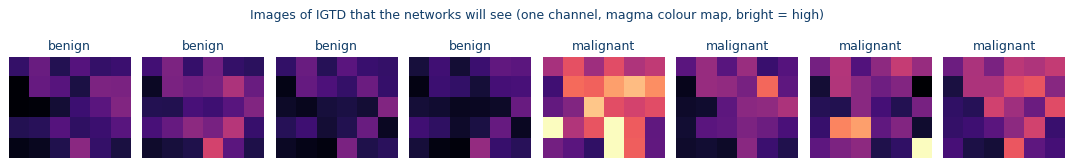

In [15]:
print("image tensor:", X_img["train"].shape, "| tokens per image for the ViT:", (H // PATCH) * (W // PATCH))

fig, axes = plt.subplots(1, 8, figsize=(12, 2.0))
examples = list(np.flatnonzero(y["train"] == 0)[:4]) + list(np.flatnonzero(y["train"] == 1)[:4])
for ax, i in zip(axes, examples):
    ax.imshow(X_img["train"][i, 0], cmap="magma", vmin=0, vmax=1, interpolation="nearest")
    ax.set_title("malignant" if y["train"][i] else "benign"); ax.axis("off")
plt.suptitle(f"Images of {METHOD} that the networks will see (one channel, magma colour map, bright = high)",
             color=NAVY, fontsize=10)
plt.tight_layout()
plt.show()

**How to read these images**

<div class="alert alert-info">
<strong>One channel, coloured for display.</strong><br>
Each image is a 20×24 matrix of numbers with <strong>a single channel</strong>: the network receives a tensor of shape <code>(1, 20, 24)</code>, not a colour image. The colours are added by <code>matplotlib</code> when it applies the <em>magma</em> colour map, which maps low values to black and purple and high values to orange and light yellow. It is used instead of a grey scale because it is perceptually uniform: the eye distinguishes small differences in value more easily.
</div>

- **Each 4×4 block is one variable.** IGTD places the 30 variables on a 5×6 grid and `zoom=4` enlarges every cell into a 4×4 block, which is why you see 5 rows and 6 columns of blocks. The variable behind each block is given by the footprints (`masks`) computed in this section.
- **Bright = high value.** After the correction of Section 7.1, every block holds the value of its variable scaled between 0 (training minimum) and 1 (training maximum). This is the opposite of the original TINTOlib IGTD images, which paint high values dark.
- **Why malignant images are brighter.** Almost every variable (size, concavity, concave points, compactness…) is larger in malignant tumours, so their images contain more bright blocks. Because IGTD places correlated variables next to each other, the bright areas tend to cluster.
- **The classes overlap.** Some malignant patients have images that look like benign ones, which is why the task is not trivial and must be evaluated as in Section 10.
- The examples are the first four patients of each class in the training partition: they illustrate the pattern, they do not prove it. Section 4.3 compares the mean image of each class.
- In validation and test some values slightly exceed 1 (patients above the training maximum). With `vmin=0, vmax=1` those pixels are displayed saturated in the brightest colour, but the network receives their actual value.

---
<div style="text-align: right">
<font size=5>
<a href="#indice">Back to index</a>
</font>
</div>

<a id="section8" name="section8"></a>
# <font color="#004D7F" size=6>8. Four architectures</font>

The image branches are written as **encoders** that return an embedding, so the same code serves the image-only models and the hybrids (Figure 6).

| Model | Image branch | Tabular branch | Fusion |
|---|---|---|---|
| **CNN** | small convolutional network | none | none |
| **ViT** | Vision Transformer on 4x4 patches | none | none |
| **HyCNN** | the same CNN | MLP on the 30 original features | concatenation |
| **HyViT** | the same ViT | MLP on the 30 original features | concatenation |

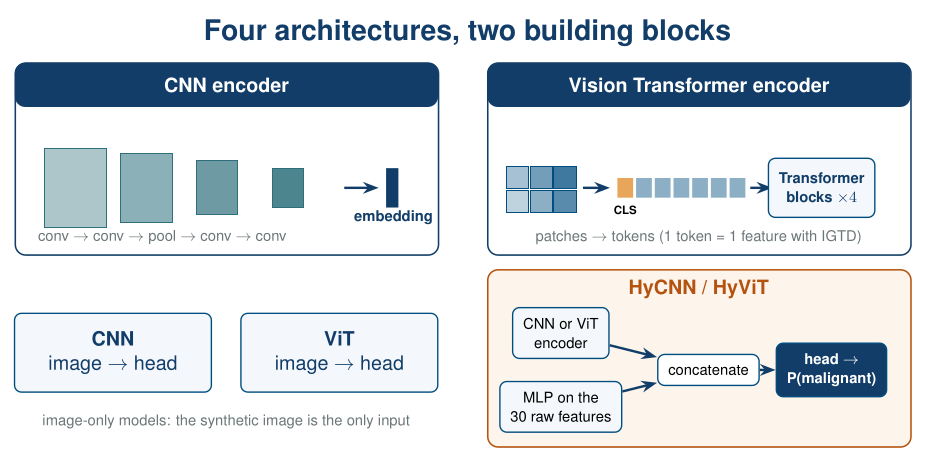

<p style="text-align:center; color:#555555;"><em><strong>Figure 6.</strong> Four architectures built from two encoders. Image-only models use the synthetic image alone; the hybrids concatenate the image embedding with an MLP embedding of the original features before the classification head.</em></p>

<a id="section81" name="section81"></a>
## <font color="#004D7F" size=5>8.1. CNN encoder</font>

In [16]:
class CNNEncoder(nn.Module):
    # Two convolutional stages, then global average pooling -> embedding
    def __init__(self, in_ch=1, width=32):
        super().__init__()
        def block(c_in, c_out):
            return nn.Sequential(nn.Conv2d(c_in, c_out, 3, padding=1), nn.BatchNorm2d(c_out), nn.ReLU())
        self.stage1 = nn.Sequential(block(in_ch, width), block(width, width), nn.MaxPool2d(2))
        self.stage2 = nn.Sequential(block(width, 2 * width), block(2 * width, 2 * width))  # Grad-CAM looks here
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.out_dim = 2 * width

    def forward(self, x):
        return self.pool(self.stage2(self.stage1(x))).flatten(1)

<a id="section82" name="section82"></a>
## <font color="#004D7F" size=5>8.2. Vision Transformer encoder</font>

The ViT is written from scratch in a few lines. Each transformer block keeps its **attention weights**, which we need for attention rollout.

In [17]:
class TransformerBlock(nn.Module):
    def __init__(self, dim, heads, mlp_ratio=2.0, dropout=0.1):
        super().__init__()
        self.norm1 = nn.LayerNorm(dim)
        self.attn = nn.MultiheadAttention(dim, heads, dropout=dropout, batch_first=True)
        self.norm2 = nn.LayerNorm(dim)
        hidden = int(dim * mlp_ratio)
        self.mlp = nn.Sequential(nn.Linear(dim, hidden), nn.GELU(), nn.Dropout(dropout),
                                 nn.Linear(hidden, dim), nn.Dropout(dropout))
        self.last_attn = None

    def forward(self, x):
        h = self.norm1(x)
        a, w = self.attn(h, h, h, need_weights=True, average_attn_weights=False)
        self.last_attn = w.detach()                  # (batch, heads, tokens, tokens)
        x = x + a
        return x + self.mlp(self.norm2(x))


class ViTEncoder(nn.Module):
    # Patchify -> linear embedding + [CLS] token + positions -> transformer blocks -> [CLS] embedding
    def __init__(self, img_size, patch=PATCH, in_ch=1, dim=64, depth=4, heads=4, dropout=0.1):
        super().__init__()
        self.grid = (img_size[0] // patch, img_size[1] // patch)
        n_tokens = self.grid[0] * self.grid[1]
        self.patch_embed = nn.Conv2d(in_ch, dim, kernel_size=patch, stride=patch)
        self.cls = nn.Parameter(torch.zeros(1, 1, dim))
        self.pos = nn.Parameter(torch.zeros(1, n_tokens + 1, dim))
        nn.init.trunc_normal_(self.cls, std=0.02)
        nn.init.trunc_normal_(self.pos, std=0.02)
        self.drop = nn.Dropout(dropout)
        self.blocks = nn.ModuleList([TransformerBlock(dim, heads, dropout=dropout) for _ in range(depth)])
        self.norm = nn.LayerNorm(dim)
        self.out_dim = dim

    def forward(self, x):
        tokens = self.patch_embed(x).flatten(2).transpose(1, 2)            # (batch, n_tokens, dim)
        cls = self.cls.expand(tokens.shape[0], -1, -1)
        tokens = self.drop(torch.cat([cls, tokens], dim=1) + self.pos)
        for block in self.blocks:
            tokens = block(tokens)
        return self.norm(tokens[:, 0])                                     # the [CLS] token

<a id="section83" name="section83"></a>
## <font color="#004D7F" size=5>8.3. Image-only and hybrid heads</font>

In [18]:
class ImageClassifier(nn.Module):
    # CNN or ViT alone: image -> logit (the tabular input is ignored)
    def __init__(self, encoder):
        super().__init__()
        self.encoder = encoder
        self.head = nn.Sequential(nn.Dropout(0.2), nn.Linear(encoder.out_dim, 1))

    def forward(self, img, tab=None):
        return self.head(self.encoder(img)).squeeze(1)


class HybridClassifier(nn.Module):
    # HyNN: image branch (CNN or ViT) + MLP branch on the original features, fused by concatenation
    def __init__(self, encoder, n_tab, hidden=64):
        super().__init__()
        self.encoder = encoder
        self.mlp = nn.Sequential(nn.Linear(n_tab, hidden), nn.ReLU(), nn.Dropout(0.2),
                                 nn.Linear(hidden, hidden), nn.ReLU())
        self.head = nn.Sequential(nn.Dropout(0.2), nn.Linear(encoder.out_dim + hidden, 64),
                                  nn.ReLU(), nn.Linear(64, 1))

    def forward(self, img, tab):
        z = torch.cat([self.encoder(img), self.mlp(tab)], dim=1)
        return self.head(z).squeeze(1)


N_TAB = len(FEATURES)
BUILDERS = {
    "CNN":   lambda: ImageClassifier(CNNEncoder()),
    "ViT":   lambda: ImageClassifier(ViTEncoder((H, W))),
    "HyCNN": lambda: HybridClassifier(CNNEncoder(), N_TAB),
    "HyViT": lambda: HybridClassifier(ViTEncoder((H, W)), N_TAB),
}
for name, build in BUILDERS.items():
    n_params = sum(p.numel() for p in build().parameters())
    print(f"{name:<6} {n_params:>8,} trainable parameters")

CNN      65,441 trainable parameters
ViT     137,217 trainable parameters
HyCNN    79,841 trainable parameters
HyViT   151,617 trainable parameters


---
<div style="text-align: right">
<font size=5>
<a href="#indice">Back to index</a>
</font>
</div>

<a id="section9" name="section9"></a>
# <font color="#004D7F" size=6>9. Training on one split</font>

<a id="section91" name="section91"></a>
## <font color="#004D7F" size=5>9.1. A stable training recipe</font>

With only 398 training and 85 validation patients, training curves are naturally noisy: one confidently wrong validation patient is enough to make the loss jump. Besides fixing the input scale (Section 7.1), the recipe below uses standard tools that make optimisation smoother:

| Ingredient | Why |
|---|---|
| **AdamW** with a moderate learning rate (5e-4) and weight decay | smaller, regularised steps |
| **Linear warm-up + cosine decay** of the learning rate | avoids early instability, especially for the ViT, and refines at the end |
| **Label smoothing** (0.05) | prevents over-confident logits, which cause loss spikes on a small validation set |
| **Gradient clipping** (norm 1.0) | caps occasional large updates |
| **Early stopping** on the validation loss (patience 20) | keeps the weights of the best epoch |

The recipe is **fixed in advance** and is not tuned on the test data. The training functions receive the data as a dictionary `{"img", "tab", "y"}` of partitions, so Section 10 can call them inside every fold.

In [19]:
def make_loader(data, split, shuffle=False, batch_size=32, seed=SEED):
    ds = TensorDataset(torch.from_numpy(data["img"][split]), torch.from_numpy(data["tab"][split]),
                       torch.from_numpy(data["y"][split].astype(np.float32)))
    gen = torch.Generator().manual_seed(seed)
    return DataLoader(ds, batch_size=batch_size, shuffle=shuffle, drop_last=shuffle, generator=gen)

@torch.no_grad()
def predict_logits(model, img, tab, batch_size=256):
    model.eval()
    out = []
    for i in range(0, len(img), batch_size):
        xb = torch.as_tensor(img[i:i + batch_size], device=DEVICE)
        tb = torch.as_tensor(tab[i:i + batch_size], device=DEVICE)
        out.append(model(xb, tb).cpu())
    return torch.cat(out)

def predict_proba(model, img, tab):
    return torch.sigmoid(predict_logits(model, img, tab)).numpy()

def train(model, data, epochs=80, lr=5e-4, weight_decay=1e-2, warmup=5, patience=20, smoothing=0.05, clip=1.0, seed=SEED):
    # data = {"img": {...}, "tab": {...}, "y": {...}} with "train" and "val" partitions
    model = model.to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    schedule = lambda e: (e + 1) / warmup if e < warmup else 0.5 * (1 + math.cos(math.pi * (e - warmup) / (epochs - warmup)))
    sched = torch.optim.lr_scheduler.LambdaLR(opt, schedule)
    loss_fn = nn.BCEWithLogitsLoss()
    train_loader = make_loader(data, "train", shuffle=True, seed=seed)
    y_val = torch.as_tensor(data["y"]["val"], dtype=torch.float32)
    history = {"train_loss": [], "val_loss": [], "val_auc": []}
    best_loss, best_state, wait = np.inf, None, 0
    for epoch in range(epochs):
        model.train()
        total, n = 0.0, 0
        for img, tab, target in train_loader:
            img, tab, target = img.to(DEVICE), tab.to(DEVICE), target.to(DEVICE)
            soft_target = target * (1 - smoothing) + 0.5 * smoothing
            opt.zero_grad()
            loss = loss_fn(model(img, tab), soft_target)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), clip)
            opt.step()
            total += loss.item() * len(target)
            n += len(target)
        sched.step()
        val_logits = predict_logits(model, data["img"]["val"], data["tab"]["val"])
        val_loss = loss_fn(val_logits, y_val).item()
        history["train_loss"].append(total / n)
        history["val_loss"].append(val_loss)
        history["val_auc"].append(roc_auc_score(data["y"]["val"], val_logits.numpy()))
        if val_loss < best_loss - 1e-4:
            best_loss, best_state, wait = val_loss, copy.deepcopy(model.state_dict()), 0
        else:
            wait += 1
            if wait >= patience:
                break
    model.load_state_dict(best_state)
    return model, history

<a id="section92" name="section92"></a>
## <font color="#004D7F" size=5>9.2. A first look at the results</font>

CNN    trained in  20.2 s, 59 epochs
ViT    trained in  10.3 s, 41 epochs
HyCNN  trained in  11.7 s, 37 epochs
HyViT  trained in  17.6 s, 69 epochs


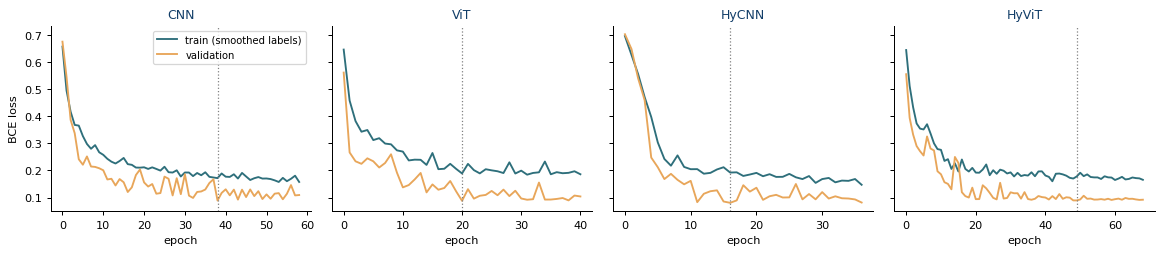

,accuracy,balanced acc.,F1 (malignant),ROC-AUC,Brier
model,,,,,
Logistic regression (table),0.965,0.953,0.951,1.000,0.026
Gradient boosting (table),0.977,0.969,0.968,0.999,0.019
CNN (image),0.977,0.969,0.968,1.000,0.015
ViT (image),1.000,1.000,1.000,1.000,0.003
HyCNN (image + table),1.000,1.000,1.000,1.000,0.007
HyViT (image + table),0.988,0.984,0.984,1.000,0.005


In [20]:
SINGLE = {"img": X_img, "tab": X_tab, "y": y}            # the 70/15/15 split of Section 3
models, histories, deep_results = {}, {}, []
for name, build in BUILDERS.items():
    set_seed()                                   # same initial conditions for every model
    t0 = time.time()
    models[name], histories[name] = train(build(), SINGLE)
    prob = predict_proba(models[name], X_img["test"], X_tab["test"])
    deep_results.append(report(name + (" (image + table)" if name.startswith("Hy") else " (image)"), y["test"], prob))
    print(f"{name:<6} trained in {time.time() - t0:5.1f} s, {len(histories[name]['val_loss'])} epochs")

fig, axes = plt.subplots(1, 4, figsize=(13, 2.9), sharey=True)
for ax, (name, h) in zip(axes, histories.items()):
    ax.plot(h["train_loss"], color=TEAL, label="train (smoothed labels)")
    ax.plot(h["val_loss"], color=ORANGE, label="validation")
    ax.axvline(int(np.argmin(h["val_loss"])), color="grey", ls=":", lw=1)
    ax.set_title(name); ax.set_xlabel("epoch")
axes[0].set_ylabel("BCE loss"); axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

pd.DataFrame(baseline_results + deep_results).set_index("model").round(3)

<div class="alert alert-warning">
<strong>Do not report this table.</strong><br>
The curves are stable, and early stopping keeps the epoch with the lowest validation loss (dotted line); the training loss stays higher because it is computed on smoothed labels and with dropout active. On this test partition of only <strong>86 patients</strong>, the ViT and HyCNN classify every patient correctly and the ViT has the lowest Brier score (0.003). Section 10 shows that this is the luck of the split: over 10 folds, the ViT is the <strong>most variable</strong> model and has the worst mean Brier score (0.034 ± 0.023).
</div>

---
<div style="text-align: right">
<font size=5>
<a href="#indice">Back to index</a>
</font>
</div>

<a id="section10" name="section10"></a>
# <font color="#004D7F" size=6>10. Reliable evaluation</font>

Section 9 answered *"does the pipeline work?"*. A paper, a thesis or a decision needs a different question answered: *"how well will each model perform on new patients, and are the differences between models real?"*. This section answers it with the same train/validation/test logic, repeated so that **every patient is used for testing** and the uncertainty can be quantified.

<a id="section101" name="section101"></a>
## <font color="#004D7F" size=5>10.1. Why one split is not enough</font>

A quick experiment makes the problem visible. We take the two tabular baselines, which train in milliseconds, and repeat the 70/15/15 split of Section 3 with 100 different random seeds. **The data, the models and the code are identical; only the split changes.**

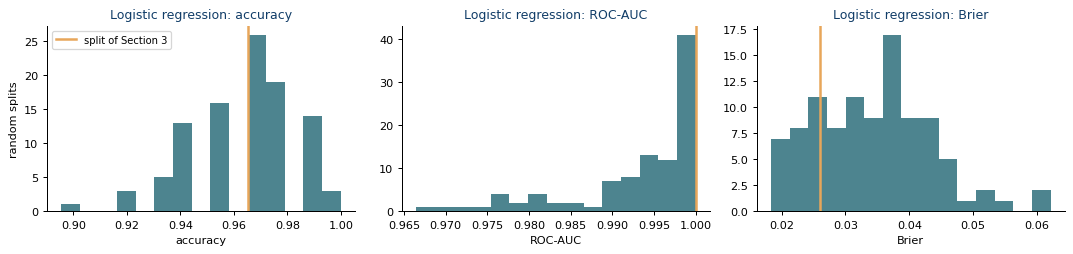

Logistic regression: test accuracy over 100 splits: min 0.895, max 1.000, central 95% [0.919, 0.994]
Gradient boosting beats logistic regression in 37% of the splits, ties in 21% and loses in 42%.


In [21]:
N_LOTTERY = 100
lottery = []
for s in range(N_LOTTERY):
    tr, rest = train_test_split(df, test_size=0.30, stratify=df["target"], random_state=s)
    _, te = train_test_split(rest, test_size=0.50, stratify=rest["target"], random_state=s)
    sc = MinMaxScaler().fit(tr[FEATURES])
    X_tr, X_te = sc.transform(tr[FEATURES]), sc.transform(te[FEATURES])
    for name, clf in [(LOGREG, LogisticRegression(max_iter=5000)), (GBOOST, HistGradientBoostingClassifier(random_state=SEED))]:
        p = clf.fit(X_tr, tr["target"]).predict_proba(X_te)[:, 1]
        lottery.append({"seed": s, "model": name, **metrics(te["target"].to_numpy(), p)})
lottery = pd.DataFrame(lottery)
lr_runs = lottery[lottery["model"] == LOGREG]

fig, axes = plt.subplots(1, 3, figsize=(12, 2.9))
for ax, m in zip(axes, [ACC, AUC, BRIER]):
    ax.hist(lr_runs[m], bins=15, color=TEAL, alpha=0.85)
    ax.axvline(baseline_results[0][m], color=ORANGE, lw=2, label="split of Section 3")
    ax.set_title(f"{LOGREG}: {m}"); ax.set_xlabel(m)
axes[0].set_ylabel("random splits"); axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

wide = lottery.pivot(index="seed", columns="model", values=ACC)
print(f"{LOGREG}: test accuracy over {N_LOTTERY} splits: min {lr_runs[ACC].min():.3f}, "
      f"max {lr_runs[ACC].max():.3f}, central 95% [{lr_runs[ACC].quantile(0.025):.3f}, {lr_runs[ACC].quantile(0.975):.3f}]")
print(f"Gradient boosting beats logistic regression in {(wide[GBOOST] > wide[LOGREG]).mean():.0%} of the splits, ties in "
      f"{(wide[GBOOST] == wide[LOGREG]).mean():.0%} and loses in {(wide[GBOOST] < wide[LOGREG]).mean():.0%}.")

Same model, same data, only the split changes: the test accuracy of logistic regression ranges from **0.895 to 1.000** (central 95%: 0.919–0.994), and our split (0.965, orange line) is just one draw. Even the winner changes: gradient boosting beats logistic regression in 37% of the splits, ties in 21% and loses in 42%. No difference between models smaller than this spread can be attributed to the models. With 569 patients a larger test set would starve training, so the standard solution is to **use every patient for testing in turn** (cross-validation) and quantify the uncertainty explicitly.

<a id="section102" name="section102"></a>
## <font color="#004D7F" size=5>10.2. Protocol: repeated stratified cross-validation</font>

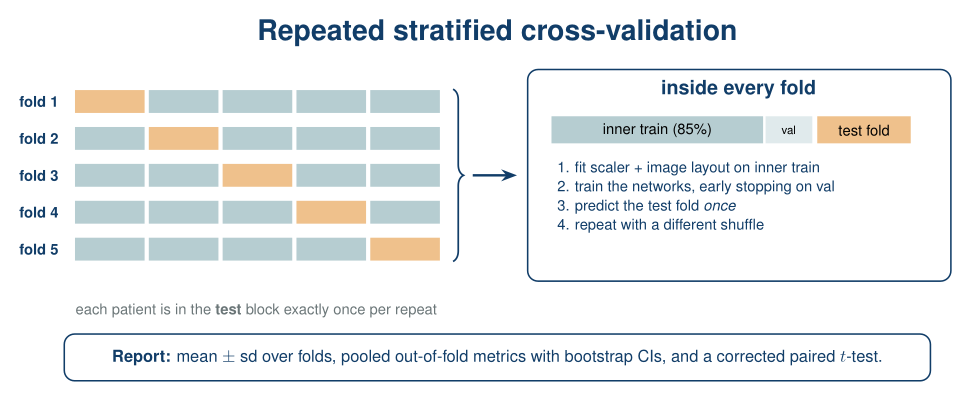

<p style="text-align:center; color:#555555;"><em><strong>Figure 7.</strong> Repeated stratified cross-validation. In every repeat the patients are shuffled and divided into five stratified folds; each fold is the test set once. Inside every fold, an inner validation partition is held out for early stopping, and everything that is learned (scaler, image layout, network weights) uses the inner training partition only.</em></p>

| Design decision | Choice | Reason |
|---|---|---|
| Outer resampling | `RepeatedStratifiedKFold`, 5 folds × 2 repeats = **10 train/test partitions** | every patient is tested once per repeat; stratification keeps 37% malignant in every fold; repeats average out the luck of one shuffle |
| Inner validation | 15% of each outer training set, stratified | used **only** for early stopping of the networks |
| What is fitted per fold | scaler, **IGTD layout**, pixel footprints and the scale check of Section 7.1, network weights | all on the inner training partition: the test fold never influences any learned quantity |
| Baselines | trained on the whole outer training set (inner train + validation) | they need no early stopping; every model sees the same outer training patients |
| Hyperparameters | fixed in advance (Section 9.1) | if you tune them, the search must run **inside** each outer training set (nested cross-validation), never on the test folds |
| Pairing | same folds and same seed for all models in a fold | differences between models can be analysed fold by fold (paired design) |
| Primary metric | **Brier score**, declared before running | proper scoring rule, sensitive to calibration, does not saturate like ROC-AUC; balanced accuracy is the secondary metric |

<div class="alert alert-info">
<strong>Why the Brier score and not the log-loss?</strong><br>
Both are proper scoring rules, but our networks are trained with label smoothing 0.05, which caps their confidence at about 0.975. That adds a floor of −ln 0.975 ≈ 0.025 to the log-loss of every correctly classified patient, a penalty that the baselines do not pay. The same cap adds only 0.025² ≈ 0.0006 to the Brier score, so the comparison remains fair.
</div>

<a id="section103" name="section103"></a>
## <font color="#004D7F" size=5>10.3. Running the protocol</font>

The first cell prepares one fold: it splits the outer training set, fits the scaler and a **fresh** IGTD on the inner training partition, computes the footprints of that fold's layout and puts every partition on the training scale with `restore_scale()` (Section 7.1), checking that the restoration is exact.

In [22]:
N_SPLITS, N_REPEATS = 5, 2          # 10 train/test partitions; use more repeats for a final paper
VAL_SIZE = 0.15                     # inner validation, used only for early stopping
MAX_RESTORE_ERROR = 0.01            # tolerance of the scale check of Section 7.1
MODEL_COL = "model"
MODEL_ORDER = [LOGREG, GBOOST, "CNN", "ViT", "HyCNN", "HyViT"]

def make_fold_data(train_idx, test_idx, seed):
    outer = df.iloc[train_idx]
    inner, val = train_test_split(outer, test_size=VAL_SIZE, stratify=outer["target"], random_state=seed)
    splits = {"train": inner.reset_index(drop=True), "val": val.reset_index(drop=True),
              "test": df.iloc[test_idx].reset_index(drop=True)}
    # Everything that is learned is fitted on the inner training partition only
    fold_scaler = MinMaxScaler().fit(splits["train"][FEATURES])
    tab = {s: fold_scaler.transform(d[FEATURES]).astype(np.float32) for s, d in splits.items()}
    method = make_method(seed)
    raw_fold = to_images(method, "cv_fold", splits, verbose=False)
    fold_masks = feature_footprints(method, splits["train"])
    img, worst_error = {}, 0.0
    for s in splits:
        img[s], best, errors = restore_scale(raw_fold[s], tab[s], fold_masks)
        worst_error = max(worst_error, errors[best])
    if worst_error > MAX_RESTORE_ERROR:
        print(f"  WARNING: scale restoration error {worst_error:.3f} > {MAX_RESTORE_ERROR}")
    y_fold = {s: d["target"].to_numpy() for s, d in splits.items()}
    return {"img": img, "tab": tab, "y": y_fold, "restore_error": worst_error, "masks": fold_masks}

def fit_baselines(data, seed):
    # Baselines need no early stopping: they use the whole outer training set (inner train + validation)
    X_fit = np.vstack([data["tab"]["train"], data["tab"]["val"]])
    y_fit = np.concatenate([data["y"]["train"], data["y"]["val"]])
    lr = LogisticRegression(max_iter=5000).fit(X_fit, y_fit)
    gb = HistGradientBoostingClassifier(random_state=seed).fit(X_fit, y_fit)
    return {LOGREG: lr.predict_proba(data["tab"]["test"])[:, 1], GBOOST: gb.predict_proba(data["tab"]["test"])[:, 1]}

The main loop trains the six models in each of the 10 folds and stores two things: the **metrics of every fold** and the **out-of-fold probability** of every patient in every repeat. In our CPU run it took 707 s (about 12 minutes); reduce `N_REPEATS` to 1 for a quick run, or increase it for a final paper (the time grows linearly).

In [23]:
cv = RepeatedStratifiedKFold(n_splits=N_SPLITS, n_repeats=N_REPEATS, random_state=SEED)
oof = {name: np.full((N_REPEATS, len(df)), np.nan) for name in MODEL_ORDER}   # out-of-fold probabilities
fold_rows = []
t_start = time.time()
for f, (train_idx, test_idx) in enumerate(cv.split(df[FEATURES], df["target"])):
    repeat, fold = divmod(f, N_SPLITS)
    seed = SEED + f
    fold_data = make_fold_data(train_idx, test_idx, seed)
    assert fold_data["img"]["train"].shape[-2:] == (H, W), "the image size must be the same in every fold"
    probs = fit_baselines(fold_data, seed)
    for name, build in BUILDERS.items():
        set_seed(seed)                   # paired design: in a fold, every network starts from the same seed
        model, _ = train(build(), fold_data, seed=seed)
        probs[name] = predict_proba(model, fold_data["img"]["test"], fold_data["tab"]["test"])
    for name, p in probs.items():
        oof[name][repeat, test_idx] = p
        fold_rows.append({"repeat": repeat, "fold": fold, MODEL_COL: name, **metrics(fold_data["y"]["test"], p)})
    print(f"repeat {repeat + 1}/{N_REPEATS} · fold {fold + 1}/{N_SPLITS} · {len(test_idx)} test patients · "
          f"Brier: " + ", ".join(f"{name} {brier_score_loss(fold_data['y']['test'], p):.3f}" for name, p in probs.items())
          + f" · {time.time() - t_start:4.0f} s")

cv_results = pd.DataFrame(fold_rows)
assert not any(np.isnan(v).any() for v in oof.values()), "every patient must be tested once per repeat"

repeat 1/2 · fold 1/5 · 114 test patients · Brier: Logistic regression 0.027, Gradient boosting 0.008, CNN 0.022, ViT 0.021, HyCNN 0.016, HyViT 0.035 ·   68 s
repeat 1/2 · fold 2/5 · 114 test patients · Brier: Logistic regression 0.044, Gradient boosting 0.047, CNN 0.050, ViT 0.084, HyCNN 0.050, HyViT 0.060 ·  120 s
repeat 1/2 · fold 3/5 · 114 test patients · Brier: Logistic regression 0.042, Gradient boosting 0.042, CNN 0.039, ViT 0.033, HyCNN 0.029, HyViT 0.029 ·  181 s
repeat 1/2 · fold 4/5 · 114 test patients · Brier: Logistic regression 0.028, Gradient boosting 0.018, CNN 0.022, ViT 0.058, HyCNN 0.020, HyViT 0.026 ·  243 s
repeat 1/2 · fold 5/5 · 113 test patients · Brier: Logistic regression 0.024, Gradient boosting 0.029, CNN 0.014, ViT 0.010, HyCNN 0.009, HyViT 0.010 ·  311 s
repeat 2/2 · fold 1/5 · 114 test patients · Brier: Logistic regression 0.030, Gradient boosting 0.021, CNN 0.028, ViT 0.016, HyCNN 0.022, HyViT 0.019 ·  400 s
repeat 2/2 · fold 2/5 · 114 test patients · Br

<a id="section104" name="section104"></a>
## <font color="#004D7F" size=5>10.4. Performance estimates</font>

We look at the results from two complementary angles:

- **Fold level** (mean ± standard deviation over the 10 folds): how much the result of one train/test partition varies. The standard deviation is *not* a confidence interval: folds share most of their training data, so they are not independent.
- **Pooled out-of-fold**: every patient has exactly one test prediction per repeat, so each metric can be computed on all 569 patients at once and averaged over repeats. A **bootstrap over patients** (1000 resamples) gives a 95% confidence interval that reflects the finite number of test patients; it does not include the variability due to retraining, which is handled by the tests of Section 10.5.

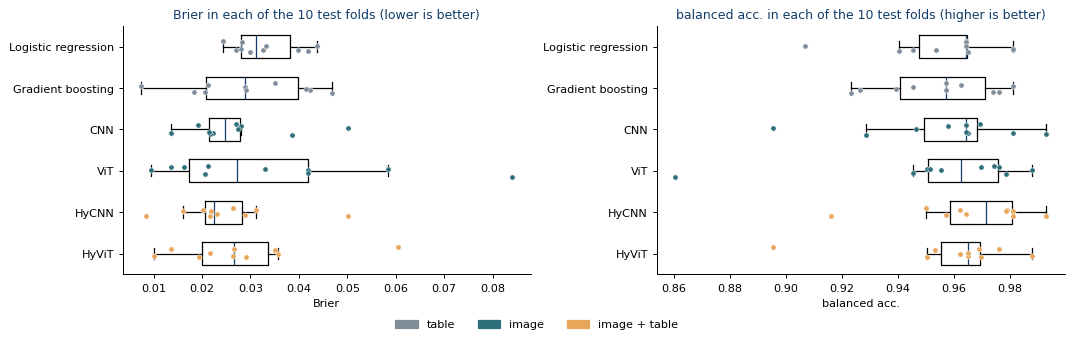

Mean ± standard deviation over folds


,Brier,balanced acc.,ROC-AUC,F1 (malignant),accuracy
model,,,,,
Logistic regression,0.033 ± 0.007,0.957 ± 0.022,0.994 ± 0.006,0.953 ± 0.024,0.967 ± 0.016
Gradient boosting,0.029 ± 0.012,0.954 ± 0.020,0.991 ± 0.007,0.947 ± 0.023,0.961 ± 0.016
CNN,0.027 ± 0.011,0.957 ± 0.028,0.994 ± 0.006,0.952 ± 0.030,0.966 ± 0.020
ViT,0.034 ± 0.023,0.955 ± 0.036,0.992 ± 0.007,0.944 ± 0.042,0.960 ± 0.027
HyCNN,0.025 ± 0.011,0.966 ± 0.022,0.995 ± 0.006,0.958 ± 0.024,0.969 ± 0.017
HyViT,0.028 ± 0.014,0.959 ± 0.025,0.995 ± 0.005,0.951 ± 0.029,0.964 ± 0.020


In [24]:
METRIC_COLS = [BRIER, BACC, AUC, F1, ACC]
KIND_COLOUR = {LOGREG: GREY, GBOOST: GREY, "CNN": TEAL, "ViT": TEAL, "HyCNN": ORANGE, "HyViT": ORANGE}

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
for ax, m in zip(axes, [BRIER, BACC]):
    values = [cv_results.loc[cv_results[MODEL_COL] == name, m].to_numpy() for name in MODEL_ORDER]
    ax.boxplot(values, vert=False, widths=0.55, showfliers=False, medianprops={"color": NAVY})
    jitter = np.random.default_rng(SEED)
    for i, (name, v) in enumerate(zip(MODEL_ORDER, values), start=1):
        ax.scatter(v, i + jitter.uniform(-0.15, 0.15, len(v)), s=18, color=KIND_COLOUR[name],
                   edgecolor="white", linewidth=0.4, zorder=3)
    ax.set_yticks(range(1, len(MODEL_ORDER) + 1))
    ax.set_yticklabels(MODEL_ORDER)
    ax.invert_yaxis()
    better = "lower is better" if m == BRIER else "higher is better"
    ax.set_title(f"{m} in each of the {len(values[0])} test folds ({better})")
    ax.set_xlabel(m)
fig.legend(handles=[Patch(color=GREY, label="table"), Patch(color=TEAL, label="image"),
                    Patch(color=ORANGE, label="image + table")],
           loc="lower center", ncol=3, frameon=False, bbox_to_anchor=(0.5, -0.06))
plt.tight_layout()
plt.show()

fold_table = pd.DataFrame({m: cv_results.groupby(MODEL_COL)[m].agg(lambda v: f"{v.mean():.3f} ± {v.std(ddof=1):.3f}")
                           for m in METRIC_COLS}).loc[MODEL_ORDER]
fold_table.index.name = MODEL_COL
print("Mean ± standard deviation over folds")
fold_table

In [25]:
N_BOOT = 1000
y_all = df["target"].to_numpy()

# Fast versions of the metrics for the bootstrap (checked against scikit-learn below)
def brier_fast(t, p):
    return np.mean((p - t) ** 2)

def bacc_fast(t, p):
    pred = p >= 0.5
    return 0.5 * (pred[t == 1].mean() + (~pred[t == 0]).mean())

def auc_fast(t, p):
    # Mann-Whitney formulation of ROC-AUC (ties count 1/2)
    r = stats.rankdata(p)
    n1 = t.sum(); n0 = len(t) - n1
    return (r[t == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)

POOLED = {BRIER: (brier_fast, brier_score_loss), BACC: (bacc_fast, balanced_accuracy_score), AUC: (auc_fast, roc_auc_score)}
p_check = oof[LOGREG][0]
for m, (fast, reference) in POOLED.items():
    ref_value = reference(y_all, (p_check >= 0.5).astype(int)) if m == BACC else reference(y_all, p_check)
    assert np.isclose(fast(y_all, p_check), ref_value), m

rng = np.random.default_rng(SEED)
boot_idx = [rng.integers(0, len(y_all), len(y_all)) for _ in range(N_BOOT)]
rows = []
for name in MODEL_ORDER:
    P = oof[name]                                    # (N_REPEATS, patients)
    row = {MODEL_COL: name}
    for m, (fast, _) in POOLED.items():
        point = np.mean([fast(y_all, p) for p in P])
        boot = [np.mean([fast(y_all[i], p[i]) for p in P]) for i in boot_idx]
        lo, hi = np.percentile(boot, [2.5, 97.5])
        row[m] = f"{point:.3f} [{lo:.3f}, {hi:.3f}]"
    rows.append(row)
pooled_table = pd.DataFrame(rows).set_index(MODEL_COL)
print(f"Pooled out-of-fold estimate on {len(y_all)} patients, mean of {N_REPEATS} repeats [95% bootstrap CI]")
pooled_table

Pooled out-of-fold estimate on 569 patients, mean of 2 repeats [95% bootstrap CI]


,Brier,balanced acc.,ROC-AUC
model,,,
Logistic regression,"0.033 [0.026, 0.041]","0.957 [0.937, 0.974]","0.993 [0.986, 0.998]"
Gradient boosting,"0.029 [0.019, 0.041]","0.954 [0.936, 0.971]","0.990 [0.982, 0.997]"
CNN,"0.027 [0.019, 0.035]","0.956 [0.939, 0.973]","0.993 [0.986, 0.998]"
ViT,"0.034 [0.023, 0.046]","0.955 [0.938, 0.970]","0.987 [0.978, 0.994]"
HyCNN,"0.025 [0.018, 0.033]","0.966 [0.951, 0.979]","0.994 [0.988, 0.998]"
HyViT,"0.028 [0.018, 0.038]","0.959 [0.944, 0.974]","0.991 [0.985, 0.997]"


**What the estimates show.** All six models are close to the ceiling and their intervals overlap: pooled Brier score from 0.025 (HyCNN) to 0.034 (ViT), balanced accuracy 0.954–0.966 and ROC-AUC 0.987–0.994. The ViT is the least stable model (Brier 0.034 ± 0.023 over folds; in its worst fold, Brier 0.084 and balanced accuracy 0.86), the opposite of what the single split of Section 9 suggested. Descriptively, each hybrid improves on its image-only counterpart (HyCNN 0.025 vs CNN 0.027; HyViT 0.028 vs ViT 0.034); whether these differences are real is tested next.

<a id="section105" name="section105"></a>
## <font color="#004D7F" size=5>10.5. Are the differences real? Corrected statistical tests</font>

To compare a model with the reference we use the paired differences of the 10 folds, $d_j = s_j^{\text{model}} - s_j^{\text{ref}}$. A naive paired $t$-test treats the $J$ differences as independent, but the training sets of different folds overlap heavily, so the fold scores are positively correlated and the naive test **underestimates the variance and finds too many "significant" differences**. The **corrected resampled $t$-test** (Nadeau & Bengio, 2003), in its repeated cross-validation form (Bouckaert & Frank, 2004), inflates the variance by the ratio of test to training size:

$$
t = \frac{\bar d}{\sqrt{\left(\dfrac{1}{J} + \dfrac{n_{\text{test}}}{n_{\text{train}}}\right)\hat\sigma^2_d}}, \qquad \frac{n_{\text{test}}}{n_{\text{train}}} = \frac{1}{k-1}, \qquad \text{df} = J-1,
$$

with $J = k \cdot r$ folds in total. We fix the reference (logistic regression), the primary metric (Brier) and the significance level (0.05) **before** looking at the results, and correct for the 5 comparisons per metric with **Holm's** method. The table also reports the 95% confidence interval of the mean difference built with the same corrected variance, and the naive $p$-value for comparison.

In [26]:
def corrected_ttest(diff, n_splits=N_SPLITS, level=0.95):
    # Corrected repeated k-fold t-test (Nadeau & Bengio, 2003; Bouckaert & Frank, 2004)
    d = np.asarray(diff, dtype=float)
    J = len(d)
    se = np.sqrt((1 / J + 1 / (n_splits - 1)) * d.var(ddof=1))
    if se == 0:
        return {"mean": d.mean(), "t": np.nan, "p": 1.0 if d.mean() == 0 else np.nan, "lo": d.mean(), "hi": d.mean()}
    t = d.mean() / se
    q = stats.t.ppf(0.5 + level / 2, df=J - 1)
    return {"mean": d.mean(), "t": t, "p": 2 * stats.t.sf(abs(t), df=J - 1),
            "lo": d.mean() - q * se, "hi": d.mean() + q * se}

def holm(pvalues):
    # Holm step-down adjustment for multiple comparisons
    p = np.nan_to_num(np.asarray(pvalues, dtype=float), nan=1.0)
    adjusted, running = np.empty_like(p), 0.0
    for rank, i in enumerate(np.argsort(p)):
        running = max(running, (len(p) - rank) * p[i])
        adjusted[i] = min(1.0, running)
    return adjusted

REFERENCE, ALPHA = LOGREG, 0.05          # fixed before looking at the results
others = [name for name in MODEL_ORDER if name != REFERENCE]
rows = []
for m, lower_is_better in [(BRIER, True), (BACC, False)]:
    per_fold = cv_results.pivot_table(index=["repeat", "fold"], columns=MODEL_COL, values=m)
    tests = [corrected_ttest(per_fold[name] - per_fold[REFERENCE]) for name in others]
    p_holm = holm([t_["p"] for t_ in tests])
    for name, res, p_adj in zip(others, tests, p_holm):
        naive = stats.ttest_rel(per_fold[name], per_fold[REFERENCE]).pvalue
        improves = res["mean"] < 0 if lower_is_better else res["mean"] > 0
        verdict = ("better" if improves else "worse") if p_adj < ALPHA else "no evidence of a difference"
        rows.append({"metric": m, MODEL_COL: name, "mean diff.": res["mean"],
                     "95% CI (corrected)": f"[{res['lo']:+.4f}, {res['hi']:+.4f}]",
                     "p naive": naive, "p corrected": res["p"], "p Holm": p_adj,
                     "verdict": verdict})
tests_table = pd.DataFrame(rows).set_index(["metric", MODEL_COL])
print(f"Differences with respect to {REFERENCE} ({N_SPLITS} folds x {N_REPEATS} repeats)")
tests_table.round(4)

Differences with respect to Logistic regression (5 folds x 2 repeats)


mean diff.  95% CI (corrected)  p naive  \
metric        model                                                        
Brier         Gradient boosting     -0.0037  [-0.0148, +0.0074]   0.1893   
              CNN                   -0.0060  [-0.0136, +0.0016]   0.0089   
              ViT                    0.0012  [-0.0251, +0.0275]   0.8541   
              HyCNN                 -0.0081  [-0.0161, -0.0001]   0.0020   
              HyViT                 -0.0050  [-0.0188, +0.0088]   0.1565   
balanced acc. Gradient boosting     -0.0023  [-0.0187, +0.0140]   0.5610   
              CNN                   -0.0001  [-0.0181, +0.0179]   0.9754   
              ViT                   -0.0017  [-0.0324, +0.0291]   0.8229   
              HyCNN                  0.0097  [-0.0084, +0.0278]   0.0491   
              HyViT                  0.0028  [-0.0189, +0.0245]   0.6001   

                                 p corrected  p Holm  \
metric        model                                    
Brier         Gradient boosting       0.4673  1.0000   
              CNN                     0.1097  0.4387   
              ViT                     0.9217  1.0000   
              HyCNN                   0.0475  0.2376   
              HyViT                   0.4299  1.0000   
balanced acc. Gradient boosting       0.7544  1.0000   
              CNN                     0.9868  1.0000   
              ViT                     0.9047  1.0000   
              HyCNN                   0.2552  1.0000   
              HyViT                   0.7781  1.0000   

                                                     verdict  
metric        model                                           
Brier         Gradient boosting  no evidence of a difference  
              CNN                no evidence of a difference  
              ViT                no evidence of a difference  
              HyCNN              no evidence of a difference  
              HyViT              no evidence of a difference  
balanced acc. Gradient boosting  no evidence of a difference  
              CNN                no evidence of a difference  
              ViT                no evidence of a difference  
              HyCNN              no evidence of a difference  
              HyViT              no evidence of a difference

**Result.** After Holm's correction, **no model differs significantly from logistic regression**, in Brier score or in balanced accuracy. The closest case is HyCNN (Brier −0.0081; corrected 95% CI [−0.0161, −0.0001]; corrected p = 0.048, Holm p = 0.24): suggestive, but not evidence once the five comparisons are taken into account.

- **The naive test would have misled us:** it gives p = 0.002 for HyCNN and p = 0.009 for the CNN. Ignoring the overlap between training sets is one of the most common statistical errors in machine learning papers.
- **"No evidence of a difference" is not evidence of equivalence.** The ViT interval spans about ±0.027 in Brier score; to claim equivalence, fix in advance the smallest relevant difference (e.g., 0.01) and check that the whole interval lies inside it.
- With 10 folds the tests have limited power; more repeats stabilise the estimates but do not create new patients.

<a id="section106" name="section106"></a>
## <font color="#004D7F" size=5>10.6. How to report the results</font>

<div class="alert alert-info">
<strong>Reporting checklist.</strong> (1) Protocol: repeated stratified cross-validation, inner validation for early stopping, every learned step fitted inside the training folds, hyperparameters fixed in advance, seeds. (2) Estimates with confidence intervals. (3) Primary metric and reference declared in advance; corrected test with multiplicity adjustment. (4) Evidence kept separate from interpretation.
</div>

**Our results, as they would appear in a paper:**

> *"Under 5×2 repeated stratified cross-validation, the hybrid HyCNN obtained the lowest pooled out-of-fold Brier score (0.025, 95% CI 0.018–0.033) versus 0.033 (0.026–0.041) for logistic regression. After Holm adjustment, the corrected resampled t-test found no evidence of a difference with respect to logistic regression for any model (HyCNN: mean difference −0.008, 95% CI −0.016 to −0.0001; Holm-adjusted p = 0.24)."*

**Interpretation.** On this near-ceiling dataset, image-based and hybrid networks are **competitive with, but not demonstrably better than**, logistic regression, an honest and legitimate result. The benefits of synthetic images reported in the literature appear mainly with few samples, many features or complex interactions, and must be demonstrated with this same protocol.

---
<div style="text-align: right">
<font size=5>
<a href="#indice">Back to index</a>
</font>
</div>

<a id="section11" name="section11"></a>
# <font color="#004D7F" size=6>11. Explainability for the CNN and the ViT</font>

A model trained on synthetic images is a black box twice over: we must explain the network **and** translate pixels back into variables. Because we know the footprint of every feature (Section 5), any pixel map can be summed into a per-feature importance (Figure 8). We explain the CNN and the ViT trained on the split of Section 9.

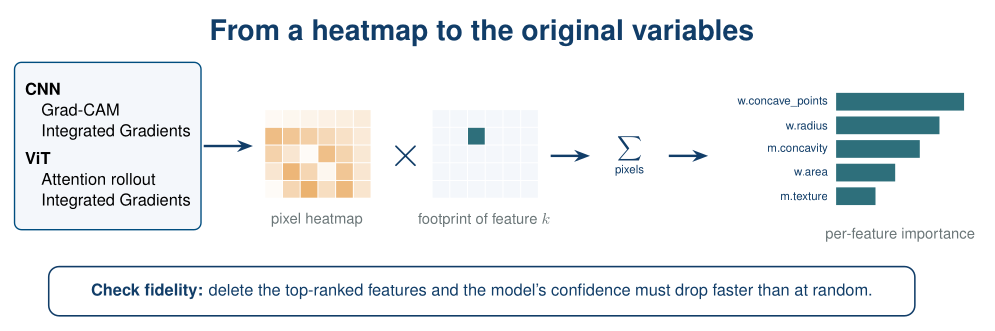

<p style="text-align:center; color:#555555;"><em><strong>Figure 8.</strong> From a heatmap to the original variables. A pixel-level explanation is multiplied by each feature's footprint and summed, giving one importance value per variable; a deletion test then checks that the ranking is faithful.</em></p>

<a id="section111" name="section111"></a>
## <font color="#004D7F" size=5>11.1. Three explanation tools</font>

| Method | Model | What it shows |
|---|---|---|
| **Grad-CAM** | CNN | Which regions of the last convolutional maps push the prediction towards the explained class |
| **Integrated Gradients (IG)** | CNN and ViT | How much each pixel contributes, relative to a reference image (the average training patient) |
| **Attention rollout** | ViT | Which tokens the [CLS] token draws information from, through all layers |

In [27]:
def per_feature(pixel_map, reduce="sum"):
    # Aggregate a pixel-level map into one value per feature using the footprints
    agg = np.sum if reduce == "sum" else np.mean
    return np.array([agg(pixel_map[m]) if m.any() else 0.0 for m in masks])

def grad_cam(model, img, sign=1.0):
    # Grad-CAM on the output of the CNN's last convolutional stage
    model.eval()
    store = {}
    hook = model.encoder.stage2.register_forward_hook(lambda mod, inp, out: store.update(act=out))
    logit = model(torch.as_tensor(img[None], device=DEVICE))
    hook.remove()
    act = store["act"]
    grad = torch.autograd.grad(sign * logit.sum(), act)[0]
    weights = grad.mean(dim=(2, 3), keepdim=True)            # importance of each channel
    cam = F.relu((weights * act).sum(1, keepdim=True))       # evidence for the explained class
    cam = F.interpolate(cam, size=img.shape[-2:], mode="bilinear", align_corners=False)[0, 0]
    return (cam / (cam.max() + 1e-12)).detach().cpu().numpy()

BASELINE = X_img["train"].mean(0)          # reference input: the average training patient

def integrated_gradients(model, img, steps=64, sign=1.0):
    # IG: average gradient along the straight path from the baseline to the input
    model.eval()
    x = torch.as_tensor(img[None], device=DEVICE)
    b = torch.as_tensor(BASELINE[None], device=DEVICE)
    alphas = (torch.arange(steps, device=DEVICE, dtype=torch.float32) + 0.5) / steps
    path = (b + alphas.view(-1, 1, 1, 1) * (x - b)).requires_grad_(True)
    grads = torch.autograd.grad(sign * model(path).sum(), path)[0]
    return ((x - b) * grads.mean(0, keepdim=True))[0, 0].detach().cpu().numpy()

@torch.no_grad()
def attention_rollout(model, img):
    # Multiply the head-averaged attention matrices of all layers (plus the residual identity)
    model.eval()
    model(torch.as_tensor(img[None], device=DEVICE))
    blocks = model.encoder.blocks
    n = blocks[0].last_attn.shape[-1]
    eye = torch.eye(n, device=DEVICE)
    rollout = eye
    for block in blocks:
        a = block.last_attn[0].mean(0) + eye
        rollout = (a / a.sum(-1, keepdim=True)) @ rollout
    cls_to_tokens = rollout[0, 1:].reshape(model.encoder.grid).cpu().numpy()
    return np.kron(cls_to_tokens, np.ones((PATCH, PATCH)))   # back to pixel resolution

**Sanity check: completeness.** Integrated Gradients has a useful property: the attributions add up to the change in the model output between the baseline and the input. If the two numbers below are close, the implementation is doing its job.

In [28]:
cnn, vit = models["CNN"], models["ViT"]
x0 = X_img["test"][patient]
for name, model in [("CNN", cnn), ("ViT", vit)]:
    with torch.no_grad():
        f_x = model(torch.as_tensor(x0[None], device=DEVICE)).item()
        f_b = model(torch.as_tensor(BASELINE[None], device=DEVICE)).item()
    ig = integrated_gradients(model, x0)
    print(f"{name}: sum of IG = {ig.sum():+.3f}   |   f(input) - f(baseline) = {f_x - f_b:+.3f}")

CNN: sum of IG = +8.289   |   f(input) - f(baseline) = +8.271
ViT: sum of IG = +4.184   |   f(input) - f(baseline) = +4.182


Both checks pass: 8.289 vs 8.271 for the CNN and 4.184 vs 4.182 for the ViT (differences below 0.3%, due to the 64-step approximation of the integral).

<a id="section112" name="section112"></a>
## <font color="#004D7F" size=5>11.2. Local explanation</font>

We explain the malignant test patient shown in the gallery. Each heatmap is overlaid on the patient's image, and the bar charts translate the IG maps into the original variables.

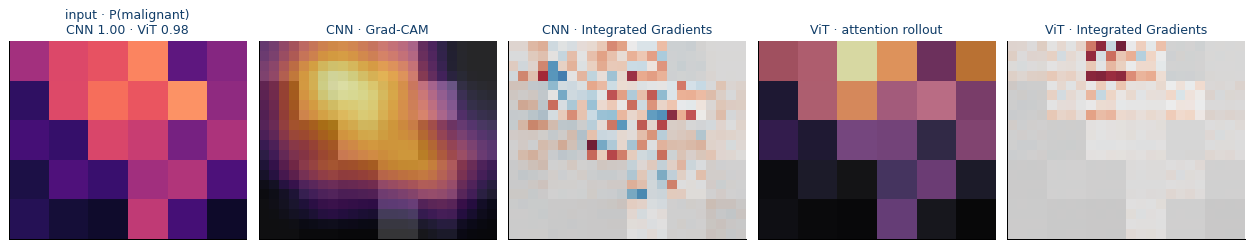

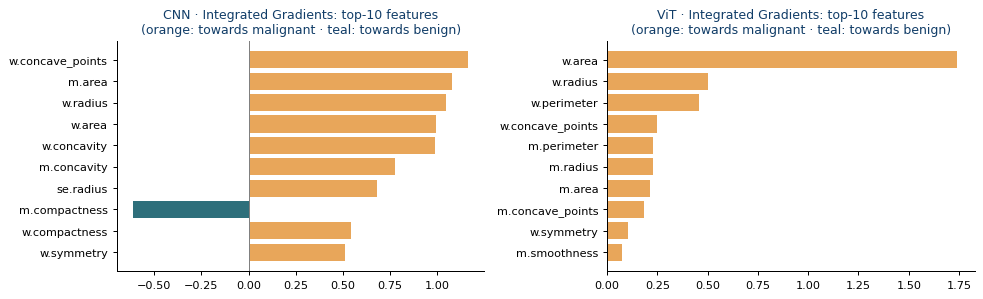

In [29]:
maps = {
    "CNN · Grad-CAM": grad_cam(cnn, x0),
    "CNN · Integrated Gradients": integrated_gradients(cnn, x0),
    "ViT · attention rollout": attention_rollout(vit, x0),
    "ViT · Integrated Gradients": integrated_gradients(vit, x0),
}
p_cnn = predict_proba(cnn, x0[None], X_tab["test"][patient:patient + 1])[0]
p_vit = predict_proba(vit, x0[None], X_tab["test"][patient:patient + 1])[0]

fig, axes = plt.subplots(1, 5, figsize=(14, 3.1))
axes[0].imshow(x0[0], cmap="magma", vmin=0, vmax=1, interpolation="nearest")
axes[0].set_title(f"input · P(malignant)\nCNN {p_cnn:.2f} · ViT {p_vit:.2f}")
for ax, (title, m) in zip(axes[1:], maps.items()):
    ax.imshow(x0[0], cmap="gray", vmin=0, vmax=1, interpolation="nearest")
    if "Integrated" in title:
        lim = np.abs(m).max() + 1e-12
        ax.imshow(m, cmap="RdBu_r", vmin=-lim, vmax=lim, alpha=0.8, interpolation="nearest")
    else:
        ax.imshow(m, cmap="inferno", alpha=0.6, interpolation="nearest")
    ax.set_title(title)
for ax in axes:
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout()
plt.show()

def short(name):
    return {"mean": "m.", "error": "se.", "worst": "w."}[group_of(name)] + measure_of(name)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
for ax, key in zip(axes, ["CNN · Integrated Gradients", "ViT · Integrated Gradients"]):
    contrib = per_feature(maps[key])
    top = np.argsort(-np.abs(contrib))[:10][::-1]
    ax.barh([short(FEATURES[k]) for k in top], contrib[top],
            color=[ORANGE if contrib[k] > 0 else TEAL for k in top])
    ax.axvline(0, color="grey", lw=0.8)
    ax.set_title(f"{key}: top-10 features\n(orange: towards malignant · teal: towards benign)")
plt.tight_layout()
plt.show()

Both models are confident for this patient (P(malignant) = 1.00 for the CNN and 0.98 for the ViT). The CNN's evidence comes mainly from size and contour variables (w.concave_points, m.area, w.radius), with m.compactness pushing slightly towards benign; the ViT relies above all on w.area.

- **Grad-CAM** is coarse: it lives at the resolution of the last convolutional layer (half the input size here) and is then upsampled. It tells you *where*, not exactly *which pixel*.
- **Integrated Gradients** is pixel-exact and signed. With IGTD every 4x4 block is one variable, so the bar chart is a direct reading of the map.
- **Attention rollout** shows where the ViT routes information. It is not class-specific: attention says what the model *looks at*, not in which direction it pushes the decision.

<a id="section113" name="section113"></a>
## <font color="#004D7F" size=5>11.3. Global explanation</font>

We average the absolute IG contribution of each feature over the whole test set, for both models, and compare the rankings with each other and with the coefficients of the logistic regression baseline.

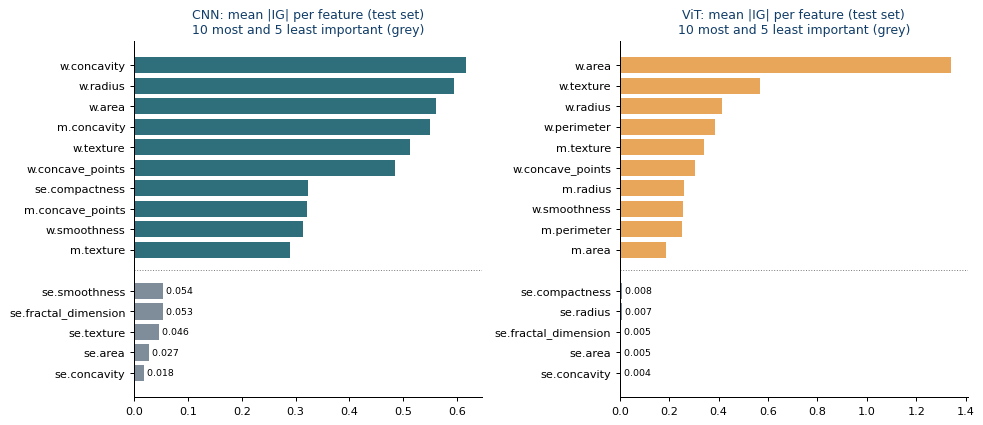

Spearman rank correlation  CNN vs ViT:                       +0.56
Spearman rank correlation  CNN vs |logistic coef.|: +0.71
Spearman rank correlation  ViT vs |logistic coef.|: +0.75


In [30]:
def global_importance(model):
    return np.mean([np.abs(per_feature(integrated_gradients(model, x, steps=32))) for x in X_img["test"]], axis=0)

imp = {"CNN": global_importance(cnn), "ViT": global_importance(vit)}
coef = np.abs(logreg.coef_[0])

TOP, BOTTOM = 10, 5                       # most and least important variables shown
fig, axes = plt.subplots(1, 2, figsize=(11, 4.8))
for ax, (name, v) in zip(axes, imp.items()):
    order = np.argsort(-v)
    shown = list(order[:TOP]) + list(order[-BOTTOM:])
    ypos = list(range(TOP)) + [TOP + 1 + i for i in range(BOTTOM)]          # a gap separates both groups
    ax.barh(ypos, v[shown], color=[TEAL if name == "CNN" else ORANGE] * TOP + [GREY] * BOTTOM)
    ax.set_yticks(ypos)
    ax.set_yticklabels([short(FEATURES[k]) for k in shown])
    ax.invert_yaxis()
    ax.axhline(TOP, color="grey", lw=0.8, ls=":")
    for yy, k in zip(ypos[TOP:], shown[TOP:]):
        ax.text(v[k], yy, f" {v[k]:.3f}", va="center", fontsize=7.5)
    ax.set_title(f"{name}: mean |IG| per feature (test set)\n{TOP} most and {BOTTOM} least important (grey)")
plt.tight_layout()
plt.show()

print(f"Spearman rank correlation  CNN vs ViT:                       {spearmanr(imp['CNN'], imp['ViT']).correlation:+.2f}")
print(f"Spearman rank correlation  CNN vs |logistic coef.|: {spearmanr(imp['CNN'], coef).correlation:+.2f}")
print(f"Spearman rank correlation  ViT vs |logistic coef.|: {spearmanr(imp['ViT'], coef).correlation:+.2f}")

**Reading the global rankings.** Both models rely on size and contour variables, and both rankings agree moderately with the logistic regression coefficients (Spearman 0.71 and 0.75) but only partly with each other (0.56): the CNN spreads importance over w.concavity, w.radius, w.area and m.concavity, while the ViT is dominated by w.area.

The five **least important** variables are all standard errors (CNN: se.smoothness, se.fractal_dimension, se.texture, se.area, se.concavity; ViT: se.compactness, se.radius, se.fractal_dimension, se.area, se.concavity), with mean |IG| close to zero (≤ 0.054 for the CNN and ≤ 0.008 for the ViT). Some carry almost no class signal, but se.area and se.radius do: they are redundant with the mean and worst values of the same measurement, so the model does not need them. **Low importance means "not used by this model", not "uninformative".**

<div class="alert alert-info">
<strong>Why does w.perimeter appear for the ViT but not for the CNN?</strong><br>
Each chart shows the top 12 of its own model, and for the CNN w.perimeter falls below 12th place. Radius, perimeter and area carry almost the same information (worst radius vs worst perimeter r = 0.993, vs worst area r = 0.985 in the training partition), so a network can use any combination of them, and IG credits the ones that network actually used. Equally good models can therefore split the credit differently. With strongly correlated variables, compare importances <strong>by group</strong> (e.g., the sum of the IG of radius, perimeter and area), not one by one.
</div>

<a id="section114" name="section114"></a>
## <font color="#004D7F" size=5>11.4. Are the explanations faithful?</font>

A heatmap is only useful if it reflects what the model really uses. A simple test: **remove** features one by one, from most to least important, by replacing their pixels with the average training value, and watch how confident the model remains in the true class. If the ranking is faithful, confidence should drop **faster** than when features are removed in random order. We track confidence rather than ROC-AUC because, on this easy dataset, the AUC stays saturated.

CNN: confidence after removing 5 / 10 features -> least important first 0.947 / 0.945 · random 0.937 / 0.897 · most important first 0.881 / 0.733 (no removal: 0.946)
ViT: confidence after removing 5 / 10 features -> least important first 0.965 / 0.965 · random 0.959 / 0.951 · most important first 0.839 / 0.631 (no removal: 0.965)


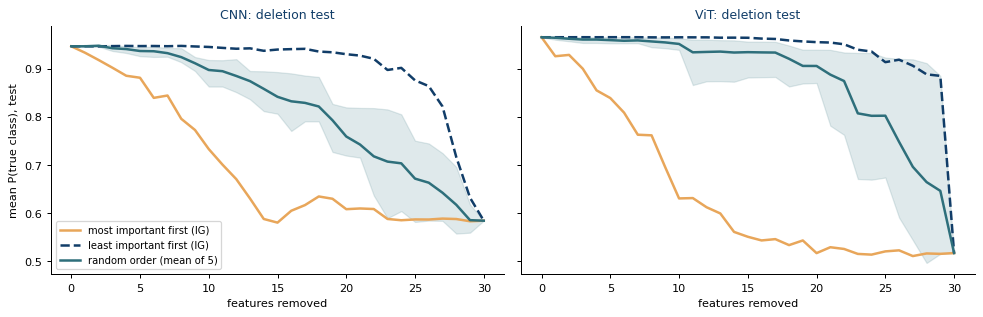

In [31]:
def confidence(model, X):
    # Mean probability the model assigns to the TRUE class of each test patient
    p = predict_proba(model, X, X_tab["test"])
    return np.mean(np.where(y["test"] == 1, p, 1 - p))

def deletion_curve(model, order):
    X = X_img["test"].copy()
    scores = [confidence(model, X)]
    for k in order:
        m = masks[k]
        X[:, :, m] = BASELINE[:, m]          # "delete" feature k: replace it by its average value
        scores.append(confidence(model, X))
    return np.array(scores)

rng = np.random.default_rng(SEED)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, (name, model) in zip(axes, [("CNN", cnn), ("ViT", vit)]):
    most = deletion_curve(model, np.argsort(-imp[name]))           # most important first
    least = deletion_curve(model, np.argsort(imp[name]))           # least important first
    random_runs = np.array([deletion_curve(model, rng.permutation(len(FEATURES))) for _ in range(5)])
    steps = np.arange(len(most))
    ax.plot(steps, most, color=ORANGE, lw=2, label="most important first (IG)")
    ax.plot(steps, least, color=NAVY, lw=2, ls="--", label="least important first (IG)")
    ax.plot(steps, random_runs.mean(0), color=TEAL, lw=2, label="random order (mean of 5)")
    ax.fill_between(steps, random_runs.min(0), random_runs.max(0), color=TEAL, alpha=0.15)
    ax.set_title(f"{name}: deletion test"); ax.set_xlabel("features removed")
    print(f"{name}: confidence after removing 5 / 10 features -> least important first {least[5]:.3f} / {least[10]:.3f} · "
          f"random {random_runs.mean(0)[5]:.3f} / {random_runs.mean(0)[10]:.3f} · most important first {most[5]:.3f} / {most[10]:.3f} "
          f"(no removal: {most[0]:.3f})")
axes[0].set_ylabel("mean P(true class), test"); axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

**Result.** Removing the variables in IG order lowers the confidence in the true class much faster than random removal (after 10 variables: 0.733 vs 0.897 for the CNN and 0.631 vs 0.951 for the ViT), while removing the **least** important first leaves it practically unchanged (CNN 0.946 → 0.945; ViT 0.965 → 0.965). The two IG curves bracket the random one, which is what faithful rankings should do.

<div class="alert alert-warning">
<strong>Caveats.</strong><br>
An explanation shows what the <strong>model</strong> uses, not what <strong>causes</strong> cancer. IG depends on the <strong>baseline</strong> (here, the average patient); a black image would tell a different story. These explanations come from <strong>one</strong> trained model on one split; to check that they are stable, repeat them on the models of several cross-validation folds and compare the rankings. Explanations become harder to trace with <strong>blurred</strong> or overlapping layouts, which is why methods with a one-to-one pixel-to-feature mapping, such as IGTD or unblurred TINTO, make auditing easier. Always pair heatmaps with a <strong>fidelity test</strong> such as the deletion curve above.
</div>

<a id="section115" name="section115"></a>
## <font color="#004D7F" size=5>11.5. Does removing the least important variables help?</font>

The deletion test removes variables from a model that was trained with all of them. A different question is whether a model **retrained without** the least important variables performs better or worse. Inside each fold of Section 10 we rank the variables with IG on the inner **validation** partition (never on the test fold, which would be leakage), replace the 5 or 10 least important ones by a constant in every partition, retrain the CNN and the ViT with the same seed and compare them with the full model using the corrected test. Removing the 5 **most** important variables serves as a contrast. The IGTD layout is kept, so only the information changes, not the image geometry.

In [32]:
# Ablation with retraining: neutralise the k least (or most) important variables, retrain and evaluate.
# The ranking is computed with IG on the inner VALIDATION partition of each fold, never on the test fold:
# choosing variables with test data and then evaluating on the same data would be leakage.
ABL_REPEATS = 1          # 1 -> first 5 folds of Section 10 (about 10 min on CPU); 2 -> all 10 folds (about 20 min)
VARIANTS = {"without 5 least important": ("least", 5),
            "without 10 least important": ("least", 10),
            "without 5 most important": ("most", 5)}           # contrast: removes the strongest evidence
FULL = "all 30 variables"

def ig_importance(model, X, baseline, fold_masks, steps=32):
    # Mean |IG| per variable over the images X, with the fold's own baseline and footprints
    model.eval()
    b = torch.as_tensor(baseline[None], device=DEVICE)
    alphas = (torch.arange(steps, device=DEVICE, dtype=torch.float32) + 0.5) / steps
    total = np.zeros(len(fold_masks))
    for x_np in X:
        x = torch.as_tensor(x_np[None], device=DEVICE)
        path = (b + alphas.view(-1, 1, 1, 1) * (x - b)).requires_grad_(True)
        grads = torch.autograd.grad(model(path).sum(), path)[0]
        attr = ((x - b) * grads.mean(0, keepdim=True))[0, 0].detach().cpu().numpy()
        total += np.abs([attr[m].sum() if m.any() else 0.0 for m in fold_masks])
    return total / len(X)

def neutralise(data, feats, baseline, fold_masks):
    # Replace the selected variables by a constant (training mean) in EVERY partition: they carry no information
    img = {}
    for split, X in data["img"].items():
        X = X.copy()
        for k in feats:
            X[:, :, fold_masks[k]] = baseline[:, fold_masks[k]]
        img[split] = X
    return {**data, "img": img}

def evaluate(model, data):
    p = predict_proba(model, data["img"]["test"], data["tab"]["test"])
    t = data["y"]["test"]
    return {BRIER: brier_score_loss(t, p), BACC: balanced_accuracy_score(t, (p >= 0.5).astype(int))}

abl_rows, least_counts = [], {"CNN": {}, "ViT": {}}
cv = RepeatedStratifiedKFold(n_splits=N_SPLITS, n_repeats=N_REPEATS, random_state=SEED)   # same folds as Section 10
t_start = time.time()
for f, (train_idx, test_idx) in enumerate(cv.split(df[FEATURES], df["target"])):
    repeat, fold = divmod(f, N_SPLITS)
    if repeat >= ABL_REPEATS:
        break
    seed = SEED + f
    fd = make_fold_data(train_idx, test_idx, seed)
    base = fd["img"]["train"].mean(0)
    visible = np.array([k for k, m in enumerate(fd["masks"]) if m.any()])
    for name in ["CNN", "ViT"]:
        set_seed(seed)
        model, _ = train(BUILDERS[name](), fd, seed=seed)
        abl_rows.append({"repeat": repeat, "fold": fold, "model": name, "variant": FULL, **evaluate(model, fd)})
        imp_val = ig_importance(model, fd["img"]["val"], base, fd["masks"])
        order = visible[np.argsort(imp_val[visible])]                   # least important first
        for k in order[:5]:
            least_counts[name][FEATURES[k]] = least_counts[name].get(FEATURES[k], 0) + 1
        for label, (which, n_drop) in VARIANTS.items():
            feats = order[:n_drop] if which == "least" else order[::-1][:n_drop]
            reduced = neutralise(fd, feats, base, fd["masks"])
            set_seed(seed)
            model_r, _ = train(BUILDERS[name](), reduced, seed=seed)
            abl_rows.append({"repeat": repeat, "fold": fold, "model": name, "variant": label, **evaluate(model_r, reduced)})
    print(f"fold {f + 1}/{ABL_REPEATS * N_SPLITS} done · {time.time() - t_start:4.0f} s")

abl = pd.DataFrame(abl_rows)
summary = []
for m in [BRIER, BACC]:
    tests = []
    for name in ["CNN", "ViT"]:
        full = abl[(abl["model"] == name) & (abl["variant"] == FULL)].set_index(["repeat", "fold"])[m]
        for label in VARIANTS:
            red = abl[(abl["model"] == name) & (abl["variant"] == label)].set_index(["repeat", "fold"])[m]
            res = corrected_ttest(red - full)
            tests.append(res)
            summary.append({"metric": m, "model": name, "variant": label, "all 30": full.mean(), "reduced": red.mean(),
                            "mean diff.": res["mean"], "95% CI (corrected)": f"[{res['lo']:+.4f}, {res['hi']:+.4f}]",
                            "p corrected": res["p"]})
    for row, p_adj in zip(summary[-len(tests):], holm([t_["p"] for t_ in tests])):
        row["p Holm"] = p_adj
abl_table = pd.DataFrame(summary).set_index(["metric", "model", "variant"])

for name, counts in least_counts.items():
    ranked = sorted(counts.items(), key=lambda kv: -kv[1])
    print(f"{name}: variables among the 5 least important (folds out of {ABL_REPEATS * N_SPLITS}): "
          + ", ".join(f"{short(v)} ({c})" for v, c in ranked))
print("Brier: lower is better · balanced acc.: higher is better · difference = reduced - all 30")
abl_table.round(4)

fold 1/5 done ·  157 s
fold 2/5 done ·  292 s
fold 3/5 done ·  439 s
fold 4/5 done ·  559 s
fold 5/5 done ·  656 s
CNN: variables among the 5 least important (folds out of 5): se.smoothness (5), m.fractal_dimension (4), se.fractal_dimension (4), se.concavity (3), m.symmetry (2), se.texture (2), m.compactness (1), m.smoothness (1), w.fractal_dimension (1), se.compactness (1), se.perimeter (1)
ViT: variables among the 5 least important (folds out of 5): se.symmetry (4), se.fractal_dimension (4), se.compactness (4), se.concavity (4), se.concave_points (3), se.perimeter (2), se.smoothness (2), se.texture (1), se.area (1)
Brier: lower is better · balanced acc.: higher is better · difference = reduced - all 30


all 30  reduced  mean diff.  \
metric        model variant                                                   
Brier         CNN   without 5 least important   0.0292   0.0315      0.0023   
                    without 10 least important  0.0292   0.0281     -0.0012   
                    without 5 most important    0.0292   0.0285     -0.0008   
              ViT   without 5 least important   0.0412   0.0331     -0.0081   
                    without 10 least important  0.0412   0.0374     -0.0037   
                    without 5 most important    0.0412   0.0270     -0.0141   
balanced acc. CNN   without 5 least important   0.9526   0.9476     -0.0051   
                    without 10 least important  0.9526   0.9620      0.0094   
                    without 5 most important    0.9526   0.9610      0.0084   
              ViT   without 5 least important   0.9458   0.9565      0.0107   
                    without 10 least important  0.9458   0.9533      0.0074   
                    without 5 most important    0.9458   0.9581      0.0123   

                                                95% CI (corrected)  \
metric        model variant                                          
Brier         CNN   without 5 least important   [-0.0094, +0.0140]   
                    without 10 least important  [-0.0123, +0.0100]   
                    without 5 most important    [-0.0168, +0.0153]   
              ViT   without 5 least important   [-0.0271, +0.0109]   
                    without 10 least important  [-0.0172, +0.0098]   
                    without 5 most important    [-0.0577, +0.0294]   
balanced acc. CNN   without 5 least important   [-0.0539, +0.0438]   
                    without 10 least important  [-0.0310, +0.0498]   
                    without 5 most important    [-0.0461, +0.0628]   
              ViT   without 5 least important   [-0.0270, +0.0484]   
                    without 10 least important  [-0.0238, +0.0387]   
                    without 5 most important    [-0.0452, +0.0698]   

                                                p corrected  p Holm  
metric        model variant                                          
Brier         CNN   without 5 least important        0.6173     1.0  
                    without 10 least important       0.7860     1.0  
                    without 5 most important         0.9026     1.0  
              ViT   without 5 least important        0.3045     1.0  
                    without 10 least important       0.4870     1.0  
                    without 5 most important         0.4180     1.0  
balanced acc. CNN   without 5 least important        0.7881     1.0  
                    without 10 least important       0.5541     1.0  
                    without 5 most important         0.6913     1.0  
              ViT   without 5 least important        0.4752     1.0  
                    without 10 least important       0.5444     1.0  
                    without 5 most important         0.5845     1.0

**Result.** No variant differs significantly from the full model (Holm p = 1.0 in every comparison, 5 folds). Removing the 5 or 10 least important variables changes the Brier score by −0.008 to +0.002, within the fold-to-fold noise: on this near-ceiling dataset, discarding them neither helps nor hurts.

- **The contrast is more revealing: removing the 5 most important variables does not hurt either** (Brier 0.0285 vs 0.0292 for the CNN). The retrained networks compensate with the remaining, highly correlated variables. IG describes what a *trained* model uses, not which variables are indispensable for the problem.
- The ViT's apparent improvements (e.g., 0.0270 vs 0.0412) reflect its instability, with one fold at Brier 0.084 as in Section 10, rather than an effect of the variables; the intervals are wide (up to [−0.058, +0.029]) and 5 folds give little power.
- The least important variables are stable across folds and almost all standard errors: se.smoothness in 5 of 5 folds for the CNN; se.symmetry, se.fractal_dimension, se.compactness and se.concavity in 4 of 5 for the ViT.
- The full models reproduce the Section 10 values for the same folds (CNN 0.029, ViT 0.041), as expected from the fixed seeds.

---
<div style="text-align: right">
<font size=5>
<a href="#indice">Back to index</a>
</font>
</div>

<a id="section12" name="section12"></a>
# <font color="#004D7F" size=6>12. Conclusions</font>

- **A synthetic image is a representation choice.** TINTOlib offers many, and they expose the same row very differently.
- **Fit on training data only**, then transform everything else with the frozen method, and **check that the same row always gives the same image**: a batch-dependent transformation silently shifts validation and test data.
- **Hybrid networks** keep the exact numbers in an MLP branch while the vision branch exploits the layout; they also recover variables that an image may hide.
- **One split is an anecdote, not an estimate.** Report repeated cross-validation with every learned step inside the training folds, confidence intervals, and corrected, multiplicity-adjusted tests against strong tabular baselines; declare the primary metric and the reference in advance.
- **Explainability must be designed in:** use traceable layouts, map pixels back to variables and test the fidelity of the explanations.
- **What this notebook found:** the best model on the single split (the ViT) is the most variable one under cross-validation, and no network is significantly better than logistic regression on this near-ceiling dataset. The explanations are faithful (deletion test in both directions), but retraining without the least or even the most important variables changes nothing significant: with redundant variables, importance describes the model, not the problem.

---
<div style="text-align: right">
<font size=5>
<a href="#indice">Back to index</a>
</font>
</div>

<a id="section13" name="section13"></a>
# <font color="#004D7F" size=6>13. Exercises</font>

1. **Another layout.** Set `METHOD = "TINTO"` in Section 7 and rerun everything, including Section 10. Which features disappear, which hypothesis does Section 7.1 select, and is TINTO better or worse than IGTD according to the corrected test? (Both runs use the same folds and seeds, so the comparison is paired; save `cv_results` before rerunning.)
2. **More repeats.** Set `N_REPEATS = 5`. How do the bootstrap intervals, the corrected confidence intervals and the verdicts change? Why does the width of the bootstrap interval barely change?
3. **Tuning without leakage.** Choose the learning rate of the CNN among {1e-3, 5e-4, 2e-4} *inside* each fold, using only the inner validation partition, and evaluate the selected model on the test fold (nested cross-validation). Compare with the fixed recipe.
4. **Remove a safeguard.** Retrain without label smoothing or without the warm-up. Look at the validation curves of Section 9 *and* at the Brier score in Section 10: which one tells you more?
5. **Blurring and Grad-CAM.** Train the CNN on `TINTO(..., blur=True)` images and compare the Grad-CAM maps with the unblurred version.
6. **Instance-centric images.** Feed the CNN with `Clusters(algorithm="kmedoids")` images. What does a pixel mean now, and can Section 11 still map it to variables?
7. **Stability of explanations.** Keep the CNN of every fold in Section 10 and compute its global IG importance on its own test fold. How stable is the ranking of the top-5 features across folds?

---
<div style="text-align: right">
<font size=5>
<a href="#indice">Back to index</a>
</font>
</div>

<a id="section14" name="section14"></a>
# <font color="#004D7F" size=6>14. References</font>

- **TINTOlib**. Documentation: https://tintolib.readthedocs.io · Code: https://github.com/oeg-upm/TINTOlib
- **TINTOlib crash course** (notebooks and videos): https://github.com/oeg-upm/TINTOlib-Crash_Course
- **Evaluation and statistics.** Nadeau, C. & Bengio, Y. (2003). *Inference for the generalization error*. Machine Learning, 52(3), 239–281 · Bouckaert, R. R. & Frank, E. (2004). *Evaluating the replicability of significance tests for comparing learning algorithms*. PAKDD, LNCS 3056, 3–12 · Dietterich, T. G. (1998). *Approximate statistical tests for comparing supervised classification learning algorithms*. Neural Computation, 10(7), 1895–1923 · Varma, S. & Simon, R. (2006). *Bias in error estimation when using cross-validation for model selection*. BMC Bioinformatics, 7, 91 · Holm, S. (1979). *A simple sequentially rejective multiple test procedure*. Scandinavian Journal of Statistics, 6(2), 65–70 · Brier, G. W. (1950). *Verification of forecasts expressed in terms of probability*. Monthly Weather Review, 78(1), 1–3.
- **Explainability.** Selvaraju, R. R. et al. (2017). *Grad-CAM*. ICCV · Sundararajan, M. et al. (2017). *Axiomatic attribution for deep networks*. ICML · Abnar, S. & Zuidema, W. (2020). *Quantifying attention flow in transformers*. ACL.
- **Blogs & Tutorials**: https://www.manuelcastillo.eu/blog/
- **Scientific Articles**:  
    - Liu, J., Castillo-Cara, M. y García-Castro, R. (2026). *A comprehensive benchmark of spatial encoding methods for tabular data with deep neural networks*. Information Fusion, 130, 104088.
    - Liu, J., González-Fernández, D., Castillo-Cara, M. y García-Castro, R. (2025). *TINTOlib: A Python library for transforming tabular data into synthetic images for deep neural networks*. SoftwareX, 32, 102444.
    - Castillo-Cara, M. et al. (2025). *MIMO-based indoor localisation with hybrid neural networks*. IEEE Journal of Selected Topics in Signal Processing, 19(3), 559–571.
    - Escalera-González, F., Castillo-Cara, M. et al. (2026). *PermGrad: Interpretable hybrid neural networks with synthetic images for tabular data*. Knowledge-Based Systems, 350, 116507.
    - Mondragon-Ruiz, G., Liu, J., Castillo-Cara, M., & García-Castro, R. (2026). Interpretable CNN–KAN hybrid architectures for tabular data with synthetic image encoding. Information Processing & Management, 63(8), 104954.
    - Martínez-Moreno, S., Liu, J., Castillo-Cara, M., Suni-Lopez, F., & García-Castro, R. (2026). CLUSTERS: Instance-Centric Synthetic Images for Tabular Learning and Functional Analysis of Hybrid Fusion.

---
<div style="text-align: right">
<font size=5>
<a href="#indice">Back to index</a>
</font>
</div>